# Evaluación de las ponderaciones espaciales del modelo de difusión Bernoulli

**Objetivo específico 2:** Desarrollar un modelo de difusión condicionado por plano anatómico y tipo de tumor para la generación de máscaras sintéticas de tumores cerebrales.

Se comparan tres configuraciones de ponderación espacial ($w_{\mathrm{ext}}\in\{0.1,0.5,1.0\}$) utilizando los historiales de entrenamiento y las máscaras sintéticas aceptadas tras el postprocesamiento. La evaluación considera características morfológicas, distancias de Wasserstein y energía, tasas de aceptación y contrastes de Kolmogorov–Smirnov y Cramér–von Mises. Este procedimiento no realiza nuevos entrenamientos ni genera máscaras.

## 1. Librerías y configuración

Se establecen las dependencias, parámetros de comparación y rutas de acceso a los experimentos Bernoulli.

In [1]:
from __future__ import annotations

import json
import re
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import cdist
from IPython.display import display

plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
})

@dataclass
class Config:
    BRISC_TRAIN_MASK_DIR: str = 'data/BRISC2025/segmentation_task/train/masks'
    EXCLUSION_CSV: str = 'data/BRISC2025/segmentation_task/train/exclusiones_oe2.csv'
    BERNOULLI_ROOT: str = 'results/OE2/difusion_bernoulli'
    OUTPUT_SUBDIR: str = 'results/OE2/evaluacion_pesos_ROI'
    PROFILE: str = 'final'
    POSTPROCESS_FOLDER: str = 'suavizado200'
    MASK_THRESHOLD_REAL: int = 127
    MASK_THRESHOLD_SYNTH: int = 0
    MASK_CONNECTIVITY: int = 2
    EXPECTED_PER_CONDITION: int = 100
    REQUIRE_EQUAL_COUNTS: bool = True
    VERIFY_SAVED_FEATURES: bool = True
    NUMERIC_TOLERANCE: float = 1e-5
    ENERGY_CHUNK: int = 384
    PLOT_DPI: int = 300
    RANDOM_SEED: int = 42
    # Igualdad distribucional: KS global ponderado con permutaciones estratificadas
    KS_N_PERMUTATIONS: int = 999
    KS_ALPHA: float = 0.05
    # CvM usa el mismo número de permutaciones y el mismo alfa por defecto
    CVM_N_PERMUTATIONS: int = 999
    CVM_ALPHA: float = 0.05

CFG = Config()

def localizar_raiz_repositorio():
    """Localiza el repositorio desde su raíz o un subdirectorio."""
    actual = Path.cwd().resolve()
    for candidato in (actual, *actual.parents):
        if (candidato / 'notebooks' / 'OE2').is_dir():
            return candidato
    raise FileNotFoundError(
        'No se encontró la raíz del repositorio (notebooks/OE2). '
        'Ejecutar JupyterLab desde la raíz o un subdirectorio del repositorio.'
    )


REPO_ROOT = localizar_raiz_repositorio()

ROOT = REPO_ROOT / CFG.BERNOULLI_ROOT
OUT = REPO_ROOT / CFG.OUTPUT_SUBDIR
FOLDERS = {
    'config': OUT / '00_configuracion',
    'wasserstein': OUT / '01_wasserstein_global',
    'energy': OUT / '02_energy_multivariada',
    'tests': OUT / '06_pruebas_igualdad_distribuciones',
    'conditional': OUT / '03_comprobacion_condicional',
    'qc': OUT / '04_aceptacion_qc',
    'summary': OUT / '05_sintesis',
    'training': OUT / '07_curvas_entrenamiento',
    'visual': OUT / '08_evaluacion_visual',
}
for folder in FOLDERS.values():
    folder.mkdir(parents=True, exist_ok=True)

WEIGHTS = [(0.1, 'roiOE1_peso01'), (0.5, 'roiOE1_peso05'), (1.0, 'roiOE1_peso10')]
MODEL_LABELS = ['w=0.1', 'w=0.5', 'w=1.0']
MODEL_MAP = {str(w): {'label': f'w={w:.1f}', 'folder': f} for w, f in WEIGHTS}
CONDITIONS = [f'{tumor}_{plane}' for tumor in ['gl','me','pi'] for plane in ['ax','co','sa']]
FEATURES = ['area_fraction','centroid_x','centroid_y','bbox_w','bbox_h','n_components']
FEATURE_NAMES = {
    'area_fraction': 'Fracción de área tumoral',
    'centroid_x': 'Centroide horizontal',
    'centroid_y': 'Centroide vertical',
    'bbox_w': 'Ancho de caja delimitadora',
    'bbox_h': 'Alto de caja delimitadora',
    'n_components': 'Número de componentes',
}
COLOR = {
    'BRISC real': '#4D4D4D', # Gris oscuro de referencia
    'w=0.1': '#6BAED6',      # Azul celeste
    'w=0.5': '#F4A261',      # Naranjo suave
    'w=1.0': '#7BC96F',      # Verde claro
}
# Se mantiene la misma paleta en TODOS los graficos del notebook.
HIST_ALPHA_REAL = 0.38
HIST_ALPHA_MODEL = 0.45
TUMOR_NAMES = {'gl': 'Glioma', 'me': 'Meningioma', 'pi': 'Pituitario'}
PLANE_NAMES = {'ax': 'axial', 'co': 'coronal', 'sa': 'sagital'}
def condition_label(condition, break_line=False):
    tumor, plane = condition.split('_')
    return f'{TUMOR_NAMES[tumor]}{chr(10) if break_line else chr(32)}{PLANE_NAMES[plane]}'

print('Referencia BRISC train:', REPO_ROOT / CFG.BRISC_TRAIN_MASK_DIR)
print('Carpeta de resultados:', OUT)
print('Tratamiento de las máscaras sintéticas:', CFG.POSTPROCESS_FOLDER)


Referencia BRISC train: K:\Tesis\Github\data\BRISC2025\segmentation_task\train\masks
Carpeta de resultados: K:\Tesis\Github\results\OE2\evaluacion_pesos_ROI
Tratamiento de las máscaras sintéticas: suavizado200


## 2. Funciones de evaluación morfológica

Se definen los descriptores geométricos y los procedimientos de ponderación y lectura de archivos.

In [2]:
VALID_EXTS = {'.png','.jpg','.jpeg','.tif','.tiff','.bmp'}
FILENAME_RE = re.compile(
    r'^brisc2025_(train|test)_(\d+)_(gl|me|pi)_(ax|co|sa)_t1$', re.IGNORECASE
)


def morphology_features_from_array(binary):
    """Calcula las seis características morfológicas de una máscara binaria."""
    binary = np.asarray(binary).astype(bool)
    if binary.ndim != 2:
        raise ValueError(f'Máscara no bidimensional: {binary.shape}')
    h, w = binary.shape
    ys, xs = np.where(binary)
    if len(xs) == 0:
        return dict(area_fraction=0.0, centroid_x=np.nan, centroid_y=np.nan,
                    bbox_w=0.0, bbox_h=0.0, n_components=0)
    structure = ndimage.generate_binary_structure(2, CFG.MASK_CONNECTIVITY)
    _, n_components = ndimage.label(binary, structure=structure)
    return {
        'area_fraction': float(binary.mean()),
        'centroid_x': float(xs.mean() / max(w-1, 1)),
        'centroid_y': float(ys.mean() / max(h-1, 1)),
        'bbox_w': float((xs.max()-xs.min()+1)/w),
        'bbox_h': float((ys.max()-ys.min()+1)/h),
        'n_components': int(n_components),
    }


def morphology_features_from_path(path, threshold):
    with Image.open(path) as img:
        data = np.asarray(img.convert('L'))
    return morphology_features_from_array(data > threshold)


def condition_weights(df):
    """Peso individual=1/(9*n_c); suma 1/9 dentro de cada condición."""
    counts = df['condition'].value_counts()
    missing = sorted(set(CONDITIONS) - set(counts.index))
    if missing:
        raise RuntimeError(f'Faltan condiciones: {missing}')
    if not set(df['condition'].unique()).issubset(set(CONDITIONS)):
        raise RuntimeError('Se encontraron condiciones desconocidas.')
    out = df['condition'].map(lambda c: 1/(len(CONDITIONS)*counts[c])).to_numpy(float)
    if not np.isclose(out.sum(), 1):
        raise RuntimeError('Los pesos globales no suman uno.')
    return out


def weighted_quantile(values, weights, quantiles):
    x = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(x)
    x, w = x[order], w[order]
    cum = (np.cumsum(w) - 0.5*w) / w.sum()
    return np.interp(quantiles, cum, x)


def weighted_summary(values, weights):
    x = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    w = w / w.sum()
    mean = np.dot(w, x)
    std = np.sqrt(np.dot(w, (x-mean)**2))
    q = weighted_quantile(x, w, [0.05,0.25,0.5,0.75,0.95])
    return dict(mean=float(mean), std=float(std), q05=float(q[0]), q25=float(q[1]),
                median=float(q[2]), q75=float(q[3]), q95=float(q[4]), min=float(x.min()), max=float(x.max()))


def save_figure(fig, folder, stem):
    folder = Path(folder)
    fig.savefig(folder / f'{stem}.png', dpi=CFG.PLOT_DPI, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)


def read_csv_or_empty(path):
    if not Path(path).exists():
        raise FileNotFoundError(f'Falta el registro original: {path}')
    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


def resolve_synthetic_mask(row, accepted_root):
    """Resuelve la máscara por condición y nombre de archivo, con ruta alternativa."""
    filename = str(row['filename'])
    condition = str(row['condition'])
    expected = accepted_root / condition / filename
    if expected.is_file():
        return expected
    path = Path(str(row.get('path', '')))
    if path.is_file():
        return path
    raise FileNotFoundError(
        f'No existe la máscara declarada para {condition}/{filename}.\n'
        f'Ruta esperada: {expected}\nRuta en manifest: {path}'
    )


## 3. Comparación de historiales de entrenamiento

Se recuperan los historiales de las tres ponderaciones y se representan las curvas de validación EMA.

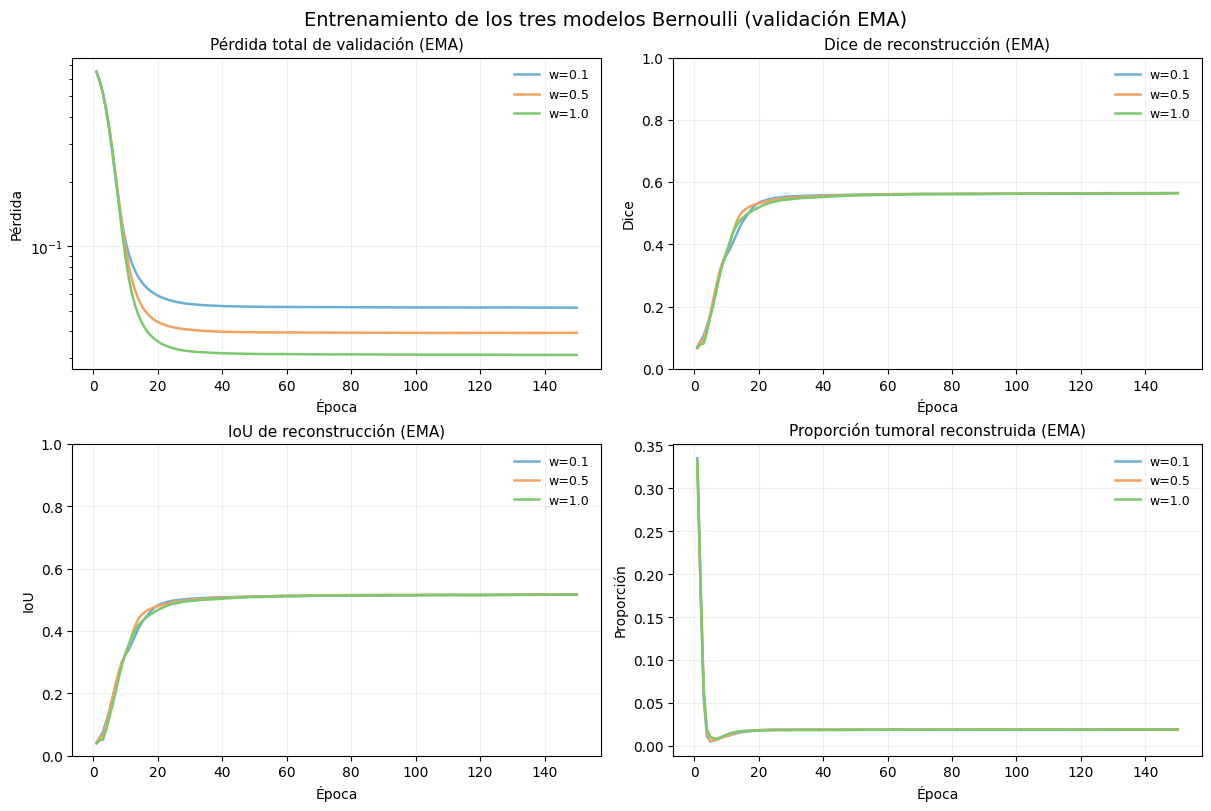

,model,weight,n_epochs_logged,first_epoch,last_epoch,best_epoch_ema,best_val_ema_total_loss,best_val_ema_dice,best_val_ema_iou,last_val_ema_total_loss,last_val_ema_dice,last_val_ema_iou,history_path
0,w=0.1,0.1,150,1,150,149,0.051573,0.565097,0.517145,0.051575,0.565233,0.517354,K:\Tesis\Github\results\OE2\difusion_bernoulli...
1,w=0.5,0.5,150,1,150,100,0.039310,0.563757,0.516684,0.039369,0.564266,0.517379,K:\Tesis\Github\results\OE2\difusion_bernoulli...
2,w=1.0,1.0,150,1,150,141,0.031031,0.564192,0.516634,0.031063,0.564646,0.517024,K:\Tesis\Github\results\OE2\difusion_bernoulli...


In [3]:
# Lectura de historiales a partir de la estructura real del OE2.
TRAIN_REQUIRED = {
    'epoch', 'val_ema_total_loss', 'val_ema_dice',
    'val_ema_iou', 'val_ema_fg_pred',
}
HISTORIES = {}
training_rows = []
for weight, folder in WEIGHTS:
    label = f'w={weight:.1f}'
    history_path = ROOT / CFG.PROFILE / folder / 'tablas' / 'history.csv'
    history = read_csv_or_empty(history_path)
    missing = TRAIN_REQUIRED - set(history.columns)
    if history.empty or missing:
        raise ValueError(f'Historial incompleto de {label}: {history_path}; faltan {sorted(missing)}')
    history = history.sort_values('epoch').reset_index(drop=True)
    if history.epoch.duplicated().any():
        raise ValueError(f'Épocas duplicadas en {history_path}')
    for col in TRAIN_REQUIRED:
        if not np.isfinite(pd.to_numeric(history[col], errors='coerce')).all():
            raise ValueError(f'Valores no finitos en {label}: {col}')
    HISTORIES[label] = history
    best = history.loc[history['val_ema_total_loss'].idxmin()]
    last = history.iloc[-1]
    training_rows.append({
        'model': label,
        'weight': weight,
        'n_epochs_logged': int(len(history)),
        'first_epoch': int(history.epoch.min()),
        'last_epoch': int(history.epoch.max()),
        'best_epoch_ema': int(best.epoch),
        'best_val_ema_total_loss': float(best.val_ema_total_loss),
        'best_val_ema_dice': float(best.val_ema_dice),
        'best_val_ema_iou': float(best.val_ema_iou),
        'last_val_ema_total_loss': float(last.val_ema_total_loss),
        'last_val_ema_dice': float(last.val_ema_dice),
        'last_val_ema_iou': float(last.val_ema_iou),
        'history_path': str(history_path),
    })

training_summary = pd.DataFrame(training_rows)
training_summary.to_csv(
    FOLDERS['training'] / 'resumen_entrenamiento_tres_modelos.csv', index=False
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
panels = [
    ('val_ema_total_loss', 'Pérdida total de validación (EMA)', 'Pérdida'),
    ('val_ema_dice', 'Dice de reconstrucción (EMA)', 'Dice'),
    ('val_ema_iou', 'IoU de reconstrucción (EMA)', 'IoU'),
    ('val_ema_fg_pred', 'Proporción tumoral reconstruida (EMA)', 'Proporción'),
]
for ax, (column, title, ylabel) in zip(axes.flat, panels):
    for label in MODEL_LABELS:
        history = HISTORIES[label]
        ax.plot(history.epoch, history[column], label=label,
                color=COLOR[label], lw=1.8)
    ax.set_title(title)
    ax.set_xlabel('Época')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.20)
    if column in {'val_ema_dice', 'val_ema_iou'}:
        ax.set_ylim(0, 1)
    if column == 'val_ema_total_loss':
        # La escala logarítmica permite observar evolución temprana y tardía.
        ax.set_yscale('log')
    ax.legend(frameon=False, fontsize=9)
fig.suptitle('Entrenamiento de los tres modelos Bernoulli (validación EMA)', fontsize=14)
save_figure(fig, FOLDERS['training'], 'curvas_entrenamiento_tres_modelos')
display(training_summary.round(6))


## 4. Conjuntos reales y sintéticos

Se leen las máscaras reales de BRISC train y las máscaras sintéticas aceptadas con suavizado $\sigma=2$, verificando su trazabilidad.

In [4]:
# 3.1 BRISC train
real_dir = REPO_ROOT / CFG.BRISC_TRAIN_MASK_DIR
if not real_dir.is_dir():
    raise FileNotFoundError(f'No existe la carpeta de BRISC train: {real_dir}')

exclude = set()
exc_file = REPO_ROOT / CFG.EXCLUSION_CSV
if exc_file.exists():
    excluded_df = pd.read_csv(exc_file)
    if 'basename' not in excluded_df.columns:
        raise ValueError('exclusiones_oe2.csv debe contener columna basename.')
    exclude = set(excluded_df['basename'].dropna().astype(str))

real_rows = []
real_skipped = []
for file in sorted(real_dir.iterdir()):
    if not file.is_file() or file.suffix.lower() not in VALID_EXTS:
        continue
    match = FILENAME_RE.match(file.stem)
    if match is None or match.group(1).lower() != 'train':
        real_skipped.append((file.name,'nombre_no_BRISC_train'))
        continue
    if file.stem in exclude:
        real_skipped.append((file.name,'exclusion_del_OE2'))
        continue
    condition = match.group(3).lower() + '_' + match.group(4).lower()
    feat = morphology_features_from_path(file, CFG.MASK_THRESHOLD_REAL)
    if feat['n_components'] == 0:
        real_skipped.append((file.name,'mascara_vacia'))
        continue
    real_rows.append({'dataset':'BRISC real','model':'BRISC real', 'weight':np.nan,
                      'condition':condition,'basename':file.stem,
                      'filename':file.name,'path':str(file), **feat})

real_df = pd.DataFrame(real_rows)
if real_df.empty:
    raise RuntimeError('No se encontraron máscaras reales válidas de entrenamiento.')
if real_df['basename'].duplicated().any():
    raise RuntimeError('Hay nombres base reales duplicados.')

pd.DataFrame(real_skipped,columns=['filename','reason']).to_csv(
    FOLDERS['config'] / 'exclusiones_reales_aplicadas.csv', index=False
)

# 3.2 Máscaras sintéticas, ya aceptadas con sigma=2
synth_parts=[]
QC_TABLES={}
AUDIT=[]
for weight, folder in WEIGHTS:
    label=f'w={weight:.1f}'
    source = ROOT / CFG.PROFILE / folder / 'mascaras_sinteticas_finales' / CFG.POSTPROCESS_FOLDER
    acc_path = source / 'manifest_accepted.csv'
    manifest = read_csv_or_empty(acc_path)
    needed = set(FEATURES + ['condition','filename'])
    if manifest.empty or not needed.issubset(manifest.columns):
        raise RuntimeError(f'Manifest inexistente, vacío o incompleto: {acc_path}\n'
                           f'Faltan: {sorted(needed-set(manifest.columns))}')
    if manifest.duplicated(['condition','filename']).any():
        raise RuntimeError(f'Máscaras duplicadas en {acc_path}')
    if 'postprocess_label' in manifest.columns:
        observed=set(manifest['postprocess_label'].dropna().unique())
        if observed != {CFG.POSTPROCESS_FOLDER}:
            raise RuntimeError(f'Postprocesamiento inesperado: {label}: {observed}')
    if 'postprocess_sigma' in manifest.columns:
        vals=pd.to_numeric(manifest['postprocess_sigma'], errors='coerce').dropna().unique()
        if len(vals)!=1 or not np.isclose(vals[0],2):
            raise RuntimeError(f'Sigma inesperado en {label}: {vals}')
    if 'qc_pass' in manifest.columns and not manifest['qc_pass'].astype(str).str.lower().eq('true').all():
        raise RuntimeError(f'El manifiesto de aceptadas contiene QC no aprobado: {label}')
    cond_counts=manifest['condition'].value_counts().reindex(CONDITIONS,fill_value=0)
    if (cond_counts==0).any():
        raise RuntimeError(f'Faltan condiciones en {label}: {cond_counts[cond_counts==0]}')
    if CFG.REQUIRE_EQUAL_COUNTS and not (cond_counts==CFG.EXPECTED_PER_CONDITION).all():
        raise RuntimeError(f'Conteos por condición distintos del objetivo '
                           f'{CFG.EXPECTED_PER_CONDITION} para {label}:\n{cond_counts}')

    accepted_root = source / 'aceptadas'
    rows=[]
    for _, row in manifest.iterrows():
        path=resolve_synthetic_mask(row,accepted_root)
        # Los PNG sintéticos se guardan con valores 0 y 255.
        feat=morphology_features_from_path(path,CFG.MASK_THRESHOLD_SYNTH)
        if CFG.VERIFY_SAVED_FEATURES:
            for name in FEATURES:
                old=float(row[name])
                new=float(feat[name])
                if not np.isfinite(old) or not np.isclose(old,new,rtol=0,atol=CFG.NUMERIC_TOLERANCE):
                    raise ValueError(f'Rasgo no coincide con manifest: {label} / {path.name} '
                                     f'{name}: guardado={old} reextraído={new}')
        rows.append({'dataset':'Sintético','model':label, 'weight':weight,
                     'condition':row['condition'], 'filename':row['filename'],
                     'path':str(path), **feat})
    synthetic=pd.DataFrame(rows)
    synth_parts.append(synthetic)
    QC_TABLES[label]={'root':source,
                      'accepted':manifest,
                      'rejected':read_csv_or_empty(source/'manifest_rejected.csv'),
                      'attempts':read_csv_or_empty(source/'manifest_attempts.csv'),
                      'summary':read_csv_or_empty(source/'resumen_aceptacion.csv')}
    for condition,count in cond_counts.items():
        AUDIT.append({'dataset':label,'condition':condition,'n_masks':int(count),
                      'source':str(source),'accepted_manifest':str(acc_path)})

synth_df=pd.concat(synth_parts,ignore_index=True)
for cond,n in real_df['condition'].value_counts().reindex(CONDITIONS,fill_value=0).items():
    AUDIT.append({'dataset':'BRISC real','condition':cond,'n_masks':int(n),
                  'source':str(real_dir),'accepted_manifest':''})

verification_df=pd.DataFrame(AUDIT)
verification_df.to_csv(FOLDERS['config']/'verificacion_archivos.csv',index=False)
count_pivot=verification_df.pivot(index='condition',columns='dataset',values='n_masks').reindex(CONDITIONS)
count_pivot.to_csv(FOLDERS['config']/'resumen_datos_utilizados.csv')

print('Máscaras reales de referencia:',len(real_df))
print('Máscaras sintéticas aceptadas:',len(synth_df))
display(count_pivot)


Máscaras reales de referencia: 3792
Máscaras sintéticas aceptadas: 2700


dataset,BRISC real,w=0.1,w=0.5,w=1.0
condition,,,,
gl_ax,394,100,100,100
gl_co,430,100,100,100
gl_sa,323,100,100,100
me_ax,348,100,100,100
me_co,400,100,100,100
me_sa,458,100,100,100
pi_ax,424,100,100,100
pi_co,502,100,100,100
pi_sa,513,100,100,100


## 5. Galería de máscaras sintéticas

Se seleccionan tres máscaras por condición y configuración mediante una semilla fija.

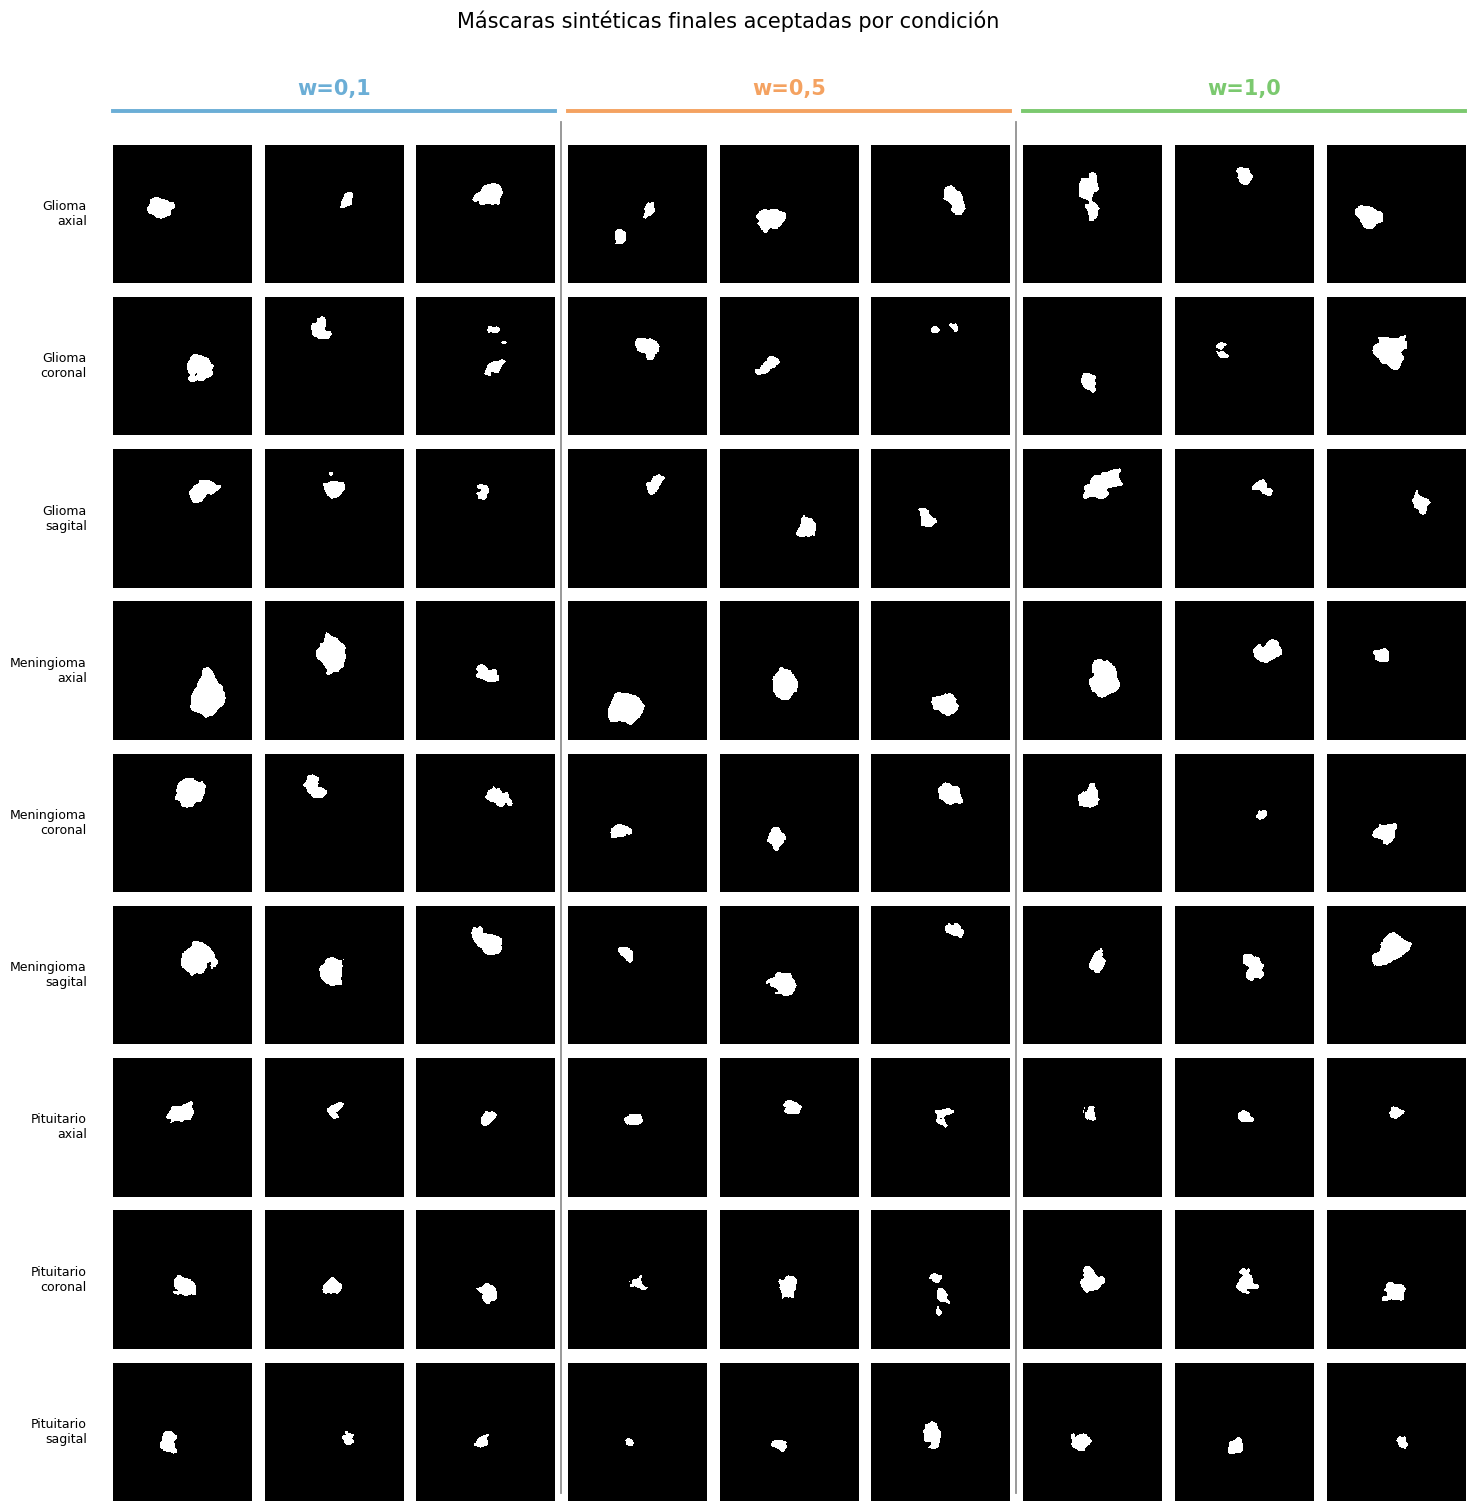

Galería: 27 máscaras por modelo, 81 máscaras en total.


condition,gl_ax,gl_co,gl_sa,me_ax,me_co,me_sa,pi_ax,pi_co,pi_sa
model,,,,,,,,,
w=0.1,3,3,3,3,3,3,3,3,3
w=0.5,3,3,3,3,3,3,3,3,3
w=1.0,3,3,3,3,3,3,3,3,3


In [5]:
def create_final_mask_gallery(synthetic, n_examples=3, seed=CFG.RANDOM_SEED):
    if n_examples != 3:
        raise ValueError('Esta galería está diseñada para tres ejemplos por condición.')
    rng = np.random.default_rng(seed)
    n_conditions = len(CONDITIONS)
    n_models = len(MODEL_LABELS)
    fig, axes = plt.subplots(
        n_conditions, n_models * n_examples,
        figsize=(15.1, 15.5), squeeze=False,
    )
    selections = []
    for mi, model in enumerate(MODEL_LABELS):
        for ri, condition in enumerate(CONDITIONS):
            part = (synthetic.loc[(synthetic['model'] == model) &
                                  (synthetic['condition'] == condition)]
                    .sort_values('filename').reset_index(drop=True))
            if len(part) < n_examples:
                raise RuntimeError(f'Solo hay {len(part)} máscaras para {model}, {condition}')
            selected_indices = rng.choice(len(part), size=n_examples, replace=False)
            for k, ind in enumerate(selected_indices):
                row = part.iloc[int(ind)]
                ax = axes[ri, mi*n_examples + k]
                mask_path = Path(str(row['path']))
                with Image.open(mask_path) as image:
                    binary = np.asarray(image.convert('L')) > CFG.MASK_THRESHOLD_SYNTH
                ax.imshow(binary, cmap='gray', vmin=0, vmax=1,
                          interpolation='nearest', aspect='equal')
                ax.set_xticks([])
                ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)
                selections.append({
                    'model': model, 'weight': float(model.split('=')[1]),
                    'condition': condition, 'condition_name': condition_label(condition),
                    'example_in_condition': k + 1, 'filename': str(row['filename']),
                    'path': str(mask_path),
                })

    # Diseño de tres bloques verticales, cada uno con tres columnas de máscaras.
    fig.subplots_adjust(left=0.09, right=0.99, bottom=0.025, top=0.90,
                        wspace=0.045, hspace=0.10)
    fig.canvas.draw()
    from matplotlib.lines import Line2D
    for ri, condition in enumerate(CONDITIONS):
        pos = axes[ri, 0].get_position()
        fig.text(0.075, (pos.y0 + pos.y1)/2,
                 condition_label(condition, break_line=True),
                 ha='right', va='center', fontsize=9)
    for mi, model in enumerate(MODEL_LABELS):
        left = axes[0, mi*n_examples].get_position().x0
        right = axes[0, mi*n_examples+n_examples-1].get_position().x1
        xcenter = (left + right)/2
        fig.text(xcenter, 0.936, model.replace('.', ','),
                 ha='center', va='center', fontsize=15,
                 weight='bold', color=COLOR[model])
        fig.add_artist(Line2D([left, right], [0.922, 0.922],
                              transform=fig.transFigure,
                              lw=2.8, color=COLOR[model]))
        if mi > 0:
            prev_right = axes[0, mi*n_examples-1].get_position().x1
            divider_x = (left + prev_right)/2
            fig.add_artist(Line2D([divider_x, divider_x], [0.03, 0.915],
                                  transform=fig.transFigure,
                                  lw=1.3, color='#555555', alpha=0.65))
    fig.suptitle('Máscaras sintéticas finales aceptadas por condición',
                 fontsize=15, y=0.987)
    selected_df = pd.DataFrame(selections)
    selected_df.to_csv(
        FOLDERS['visual'] / 'galeria_mascaras_seleccionadas.csv', index=False
    )
    save_figure(fig, FOLDERS['visual'], 'galeria_mascaras_finales_tres_modelos')
    if len(selected_df) != 81:
        raise RuntimeError('La galería no contiene las 81 máscaras esperadas.')
    print('Galería: 27 máscaras por modelo, 81 máscaras en total.')
    display(selected_df.groupby(['model', 'condition']).size().unstack())
    return selected_df

GALERIA_SELECCION = create_final_mask_gallery(synth_df, n_examples=3)


## 6. Ponderación y estandarización

Se asigna el mismo peso a las nueve condiciones y se estandarizan las características mediante la referencia real.

In [6]:
real_df=real_df.copy()
synth_df=synth_df.copy()
real_df['mix_weight']=condition_weights(real_df)
synth_df['mix_weight']=np.nan
for model in MODEL_LABELS:
    subset=synth_df.loc[synth_df['model']==model]
    synth_df.loc[subset.index,'mix_weight']=condition_weights(subset)

standardization=[]
for feature in FEATURES:
    values=real_df[feature].to_numpy(float)
    weights=real_df['mix_weight'].to_numpy(float)
    mu=float(np.dot(weights,values))
    std=float(np.sqrt(np.dot(weights,(values-mu)**2)))
    if not np.isfinite(std) or std<=0:
        raise RuntimeError(f'No se puede estandarizar {feature}: desviación real = {std}')
    standardization.append({'feature':feature,'mean_real_weighted':mu,'std_real_weighted':std})

scales_df=pd.DataFrame(standardization)
scales_df.to_csv(FOLDERS['config']/'parametros_estandarizacion.csv',index=False)
SCALES=scales_df.set_index('feature')
for feature in FEATURES:
    mu=SCALES.loc[feature,'mean_real_weighted']
    std=SCALES.loc[feature,'std_real_weighted']
    real_df[feature+'_z']=(real_df[feature]-mu)/std
    synth_df[feature+'_z']=(synth_df[feature]-mu)/std

for df in (real_df,synth_df):
    if not np.isfinite(df[[f+'_z' for f in FEATURES]].to_numpy()).all():
        raise RuntimeError('Aparecieron atributos no finitos en la estandarización.')

# Estadísticos descriptivos — distribución global equilibrada, y por condición
stats_rows=[]
for label,df in [('BRISC real',real_df)]+[(name,synth_df.query('model == @name')) for name in MODEL_LABELS]:
    for feature in FEATURES:
        for condition in ['GLOBAL_EQUILIBRADO']+CONDITIONS:
            part=df if condition=='GLOBAL_EQUILIBRADO' else df.loc[df['condition']==condition]
            weights=(part['mix_weight'].to_numpy(float) if condition=='GLOBAL_EQUILIBRADO'
                     else np.ones(len(part),dtype=float)/len(part))
            desc=weighted_summary(part[feature],weights)
            stats_rows.append({'dataset':label,'condition':condition,'feature':feature,
                               'n':len(part),**desc})
stats_df=pd.DataFrame(stats_rows)
stats_df.to_csv(FOLDERS['wasserstein']/'estadisticos_descriptivos.csv',index=False)
display(scales_df)


,feature,mean_real_weighted,std_real_weighted
0,area_fraction,0.016097,0.012794
1,centroid_x,0.495732,0.100558
2,centroid_y,0.458372,0.118564
3,bbox_w,0.153890,0.064457
4,bbox_h,0.150775,0.068194
5,n_components,1.058285,0.266273


## 7. Distancia de Wasserstein

Se calculan las distancias de Wasserstein de orden uno por característica y su promedio global estandarizado.

In [7]:
wasserstein_rows=[]
for model in MODEL_LABELS:
    syn=synth_df.loc[synth_df['model']==model]
    for feature in FEATURES:
        key=feature+'_z'
        distance=wasserstein_distance(
            real_df[key].to_numpy(float),syn[key].to_numpy(float),
            u_weights=real_df['mix_weight'].to_numpy(float),
            v_weights=syn['mix_weight'].to_numpy(float)
        )
        wasserstein_rows.append({'model':model,'weight':float(model.split('=')[1]),
                                'feature':feature,'wasserstein_1_standardized':float(distance)})

wasserstein_df=pd.DataFrame(wasserstein_rows)
w_global=(wasserstein_df.groupby(['model','weight'],as_index=False)['wasserstein_1_standardized']
          .mean().rename(columns={'wasserstein_1_standardized':'wasserstein_global_mean_6'}))
w_global=w_global.sort_values('weight')
w_global['rank_wasserstein_global']=w_global['wasserstein_global_mean_6'].rank(method='min').astype(int)
wasserstein_df.to_csv(FOLDERS['wasserstein']/'wasserstein_por_caracteristica.csv',index=False)
w_global.to_csv(FOLDERS['wasserstein']/'wasserstein_global_resumen.csv',index=False)
display(w_global.round(6))
display(wasserstein_df.pivot(index='feature',columns='model',values='wasserstein_1_standardized').round(5))


,model,weight,wasserstein_global_mean_6,rank_wasserstein_global
0,w=0.1,0.1,0.111589,2
1,w=0.5,0.5,0.142514,3
2,w=1.0,1.0,0.103299,1


model,w=0.1,w=0.5,w=1.0
feature,,,
area_fraction,0.14438,0.15690,0.12603
bbox_h,0.12263,0.18523,0.12898
bbox_w,0.11021,0.16006,0.08722
centroid_x,0.05175,0.03905,0.05394
centroid_y,0.07826,0.04428,0.05839
n_components,0.16232,0.26956,0.16524


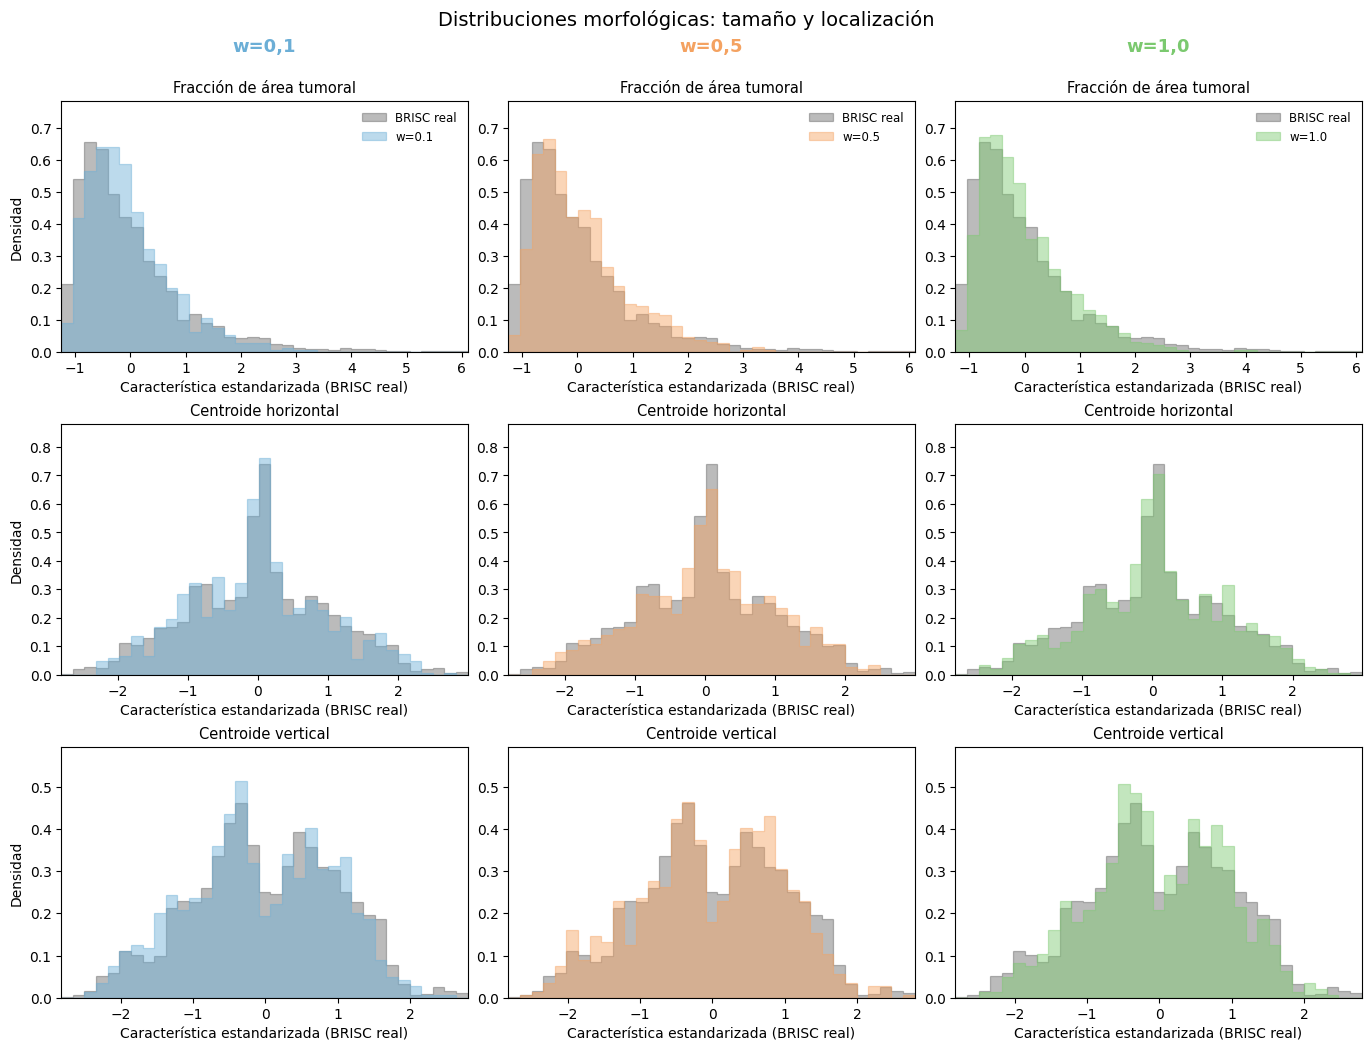

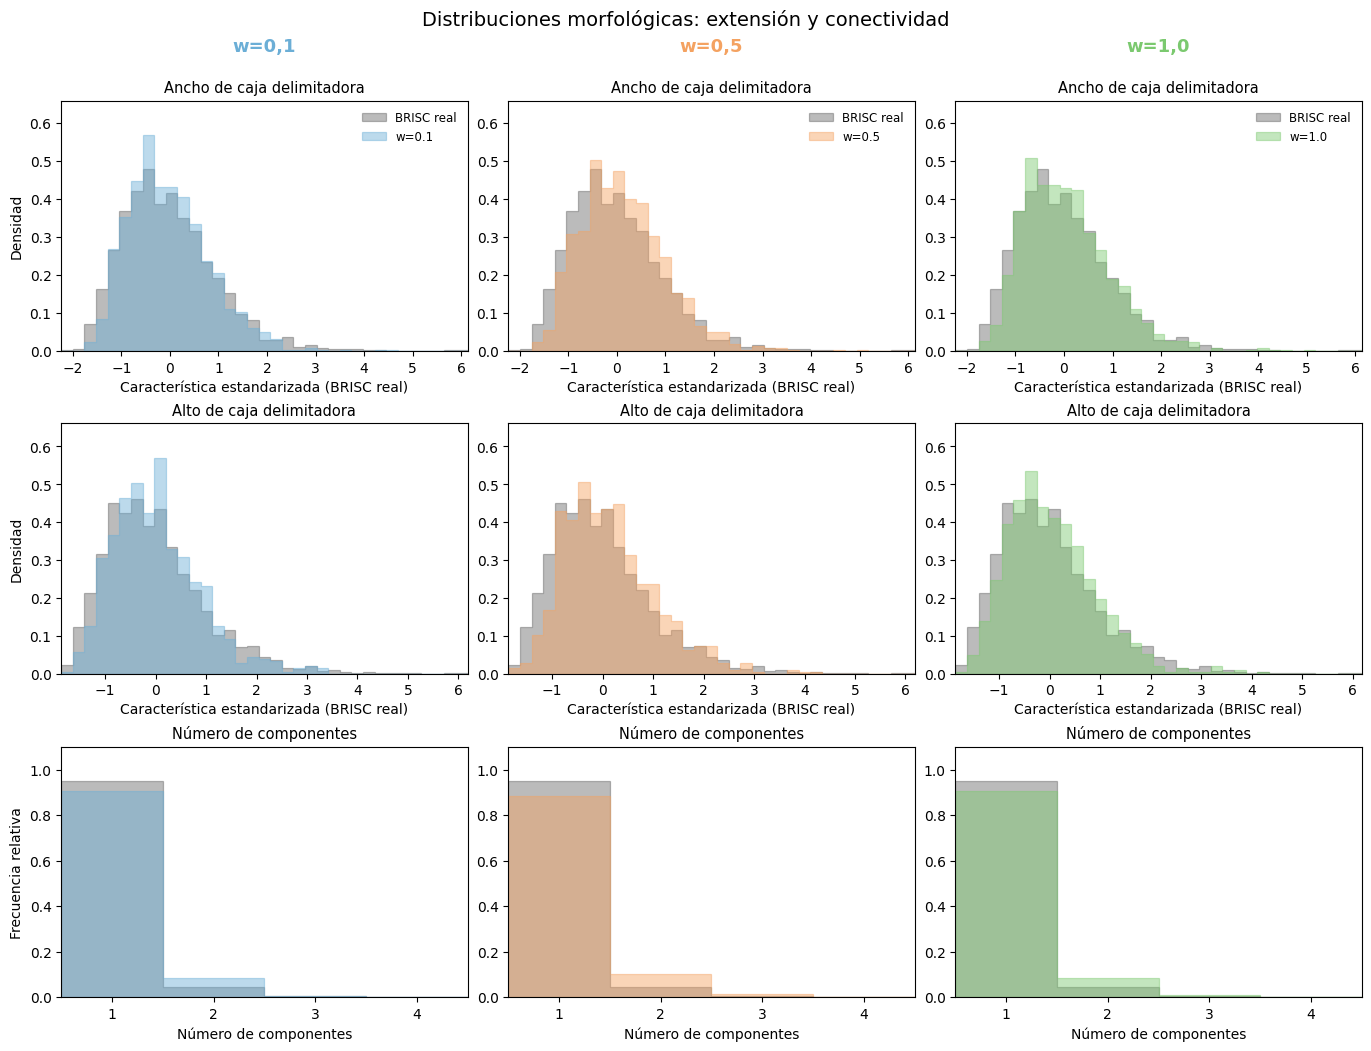

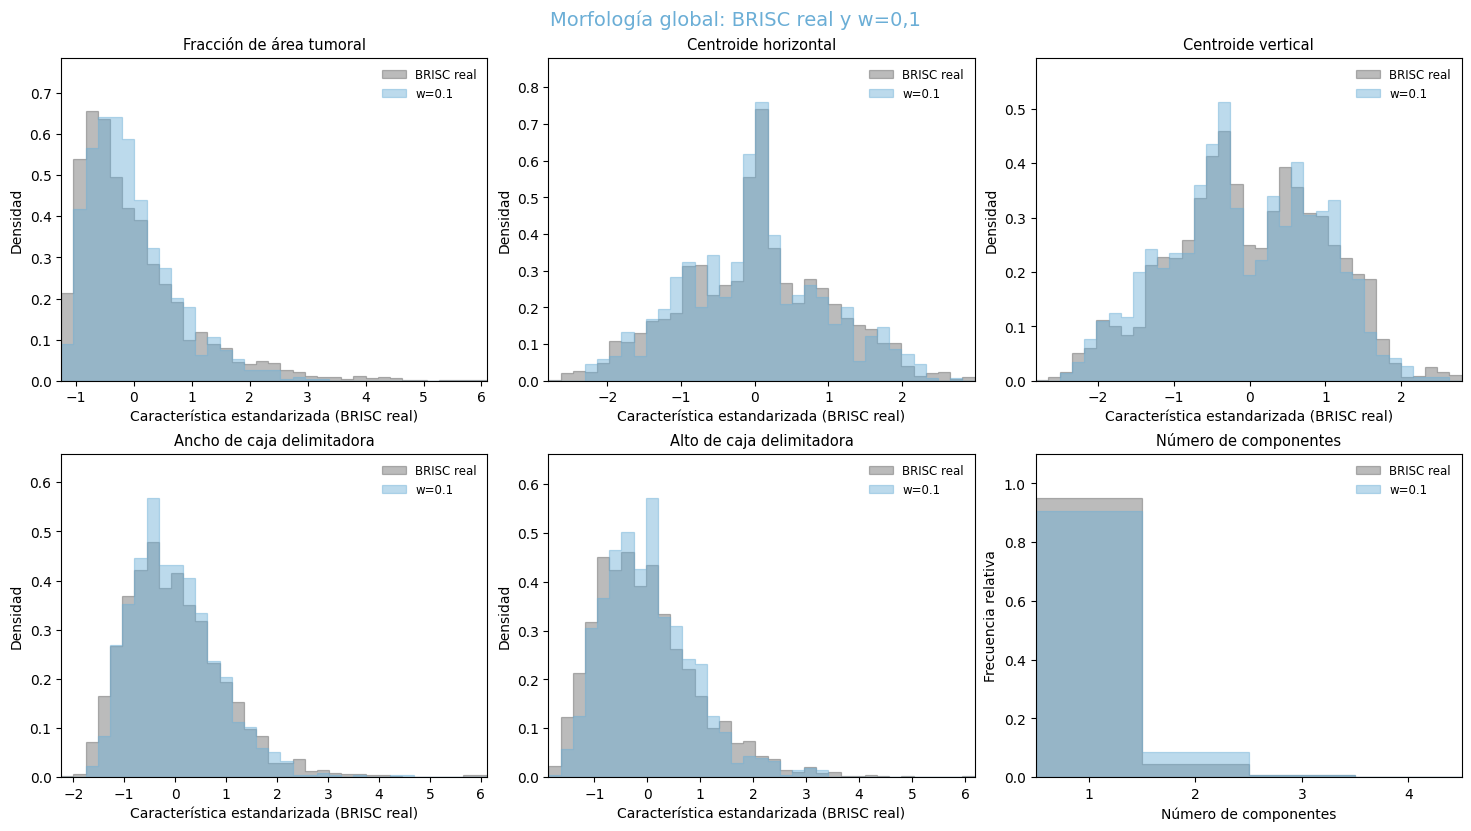

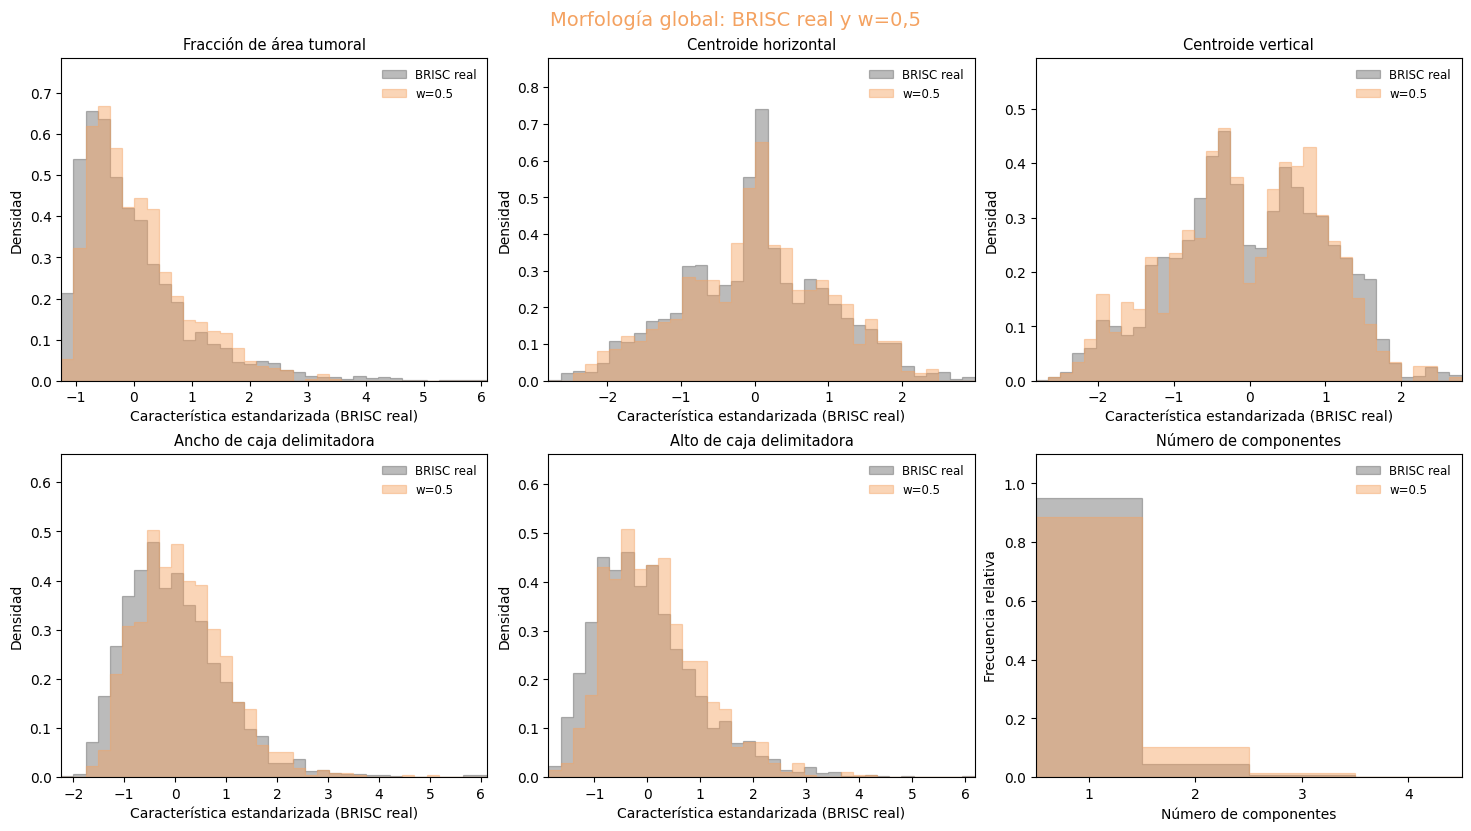

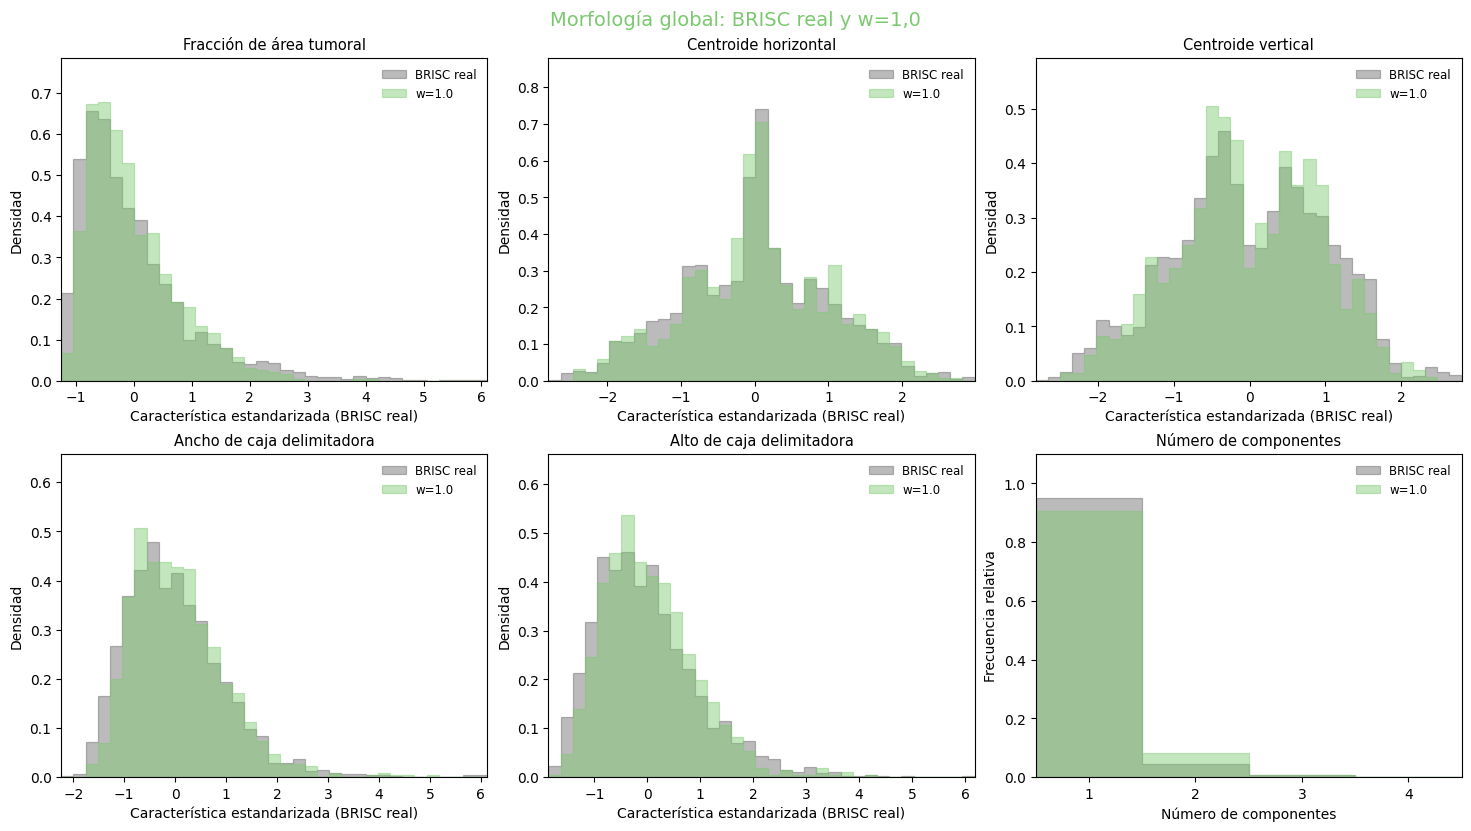

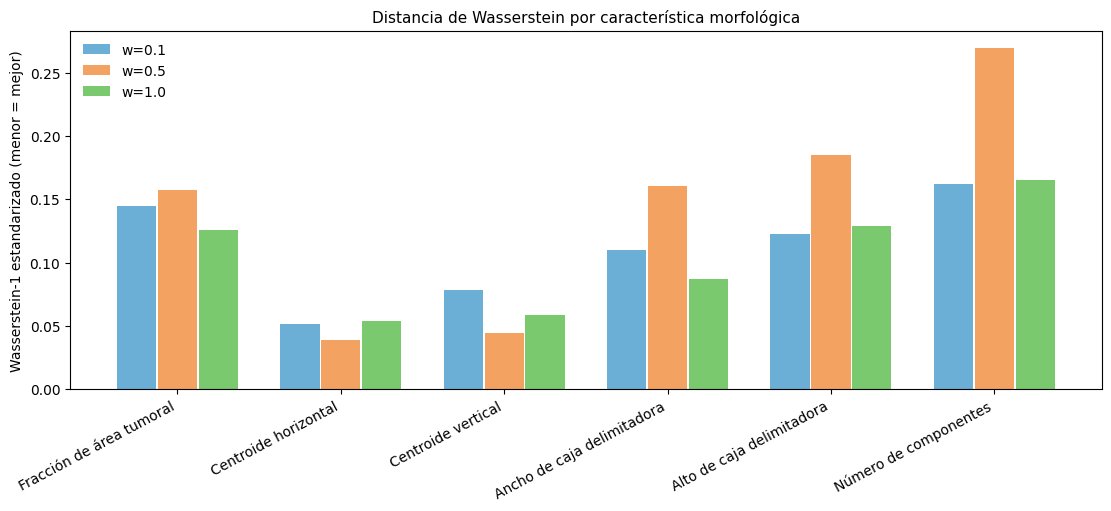

In [8]:
# ============================================================
# HISTOGRAMAS RELLENOS CON TRANSPARENCIA.
# Las figuras mantienen 1 comparación real/sintético por panel.
# Se preservan la estandarización y los pesos de las 9 condiciones.
# ============================================================

def morphological_plot_data(feature):
    """Devuelve valores y pesos para todos los modelos, con bins comunes.

    Variables continuas: z-score con parámetros del BRISC real equilibrado.
    Número de componentes: conteos enteros originales, sin suavizado de KDE.
    """
    discrete = feature == 'n_components'
    key = feature if discrete else feature + '_z'
    series = {'BRISC real': real_df}
    series.update({m: synth_df.loc[synth_df['model'] == m] for m in MODEL_LABELS})
    values = {name: frame[key].to_numpy(float) for name, frame in series.items()}
    weights = {name: frame['mix_weight'].to_numpy(float) for name, frame in series.items()}
    all_values = np.concatenate(list(values.values()))
    if not np.isfinite(all_values).all():
        raise RuntimeError(f'Característica no finita para el histograma: {feature}')
    if discrete:
        lo, hi = int(np.floor(all_values.min())), int(np.ceil(all_values.max()))
        edges = np.arange(lo - 0.5, hi + 1.5, 1.0)
        ticks = np.arange(lo, hi + 1)
    else:
        lo, hi = float(all_values.min()), float(all_values.max())
        if np.isclose(lo, hi):
            lo, hi = lo - 0.5, hi + 0.5
        edges = np.linspace(lo, hi, 36)  # 35 bins, comunes a los 3 modelos.
        ticks = None
    # Fijar límite Y común para cada característica: comparación honesta entre pesos.
    ymax = 0.0
    for name in values:
        heights = np.histogram(values[name], bins=edges, weights=weights[name])[0]
        if not discrete:
            heights = heights / np.diff(edges)
        ymax = max(ymax, float(heights.max()))
    return dict(discrete=discrete, values=values, weights=weights,
                edges=edges, ticks=ticks, ymax=max(ymax*1.16, 1e-6))

PLOT_CACHE = {feature: morphological_plot_data(feature) for feature in FEATURES}


def draw_morphological_overlay(ax, feature, model, legend=False):
    """Histograma de BRISC y un peso, ambos rellenos y semitransparentes."""
    info = PLOT_CACHE[feature]
    discrete = info['discrete']
    bin_edges = info['edges']
    for name, alpha in [('BRISC real', HIST_ALPHA_REAL), (model, HIST_ALPHA_MODEL)]:
        ax.hist(
            info['values'][name], bins=bin_edges,
            weights=info['weights'][name],
            density=not discrete,
            histtype='stepfilled',
            color=COLOR[name], edgecolor=COLOR[name],
            linewidth=0.9, alpha=alpha, label=name,
        )
    ax.set_xlim(bin_edges[0], bin_edges[-1])
    ax.set_ylim(0, info['ymax'])
    if discrete:
        ticks = info['ticks']
        step = max(1, int(np.ceil(len(ticks) / 10)))
        ax.set_xticks(ticks[::step])
        ax.set_xlabel('Número de componentes')
    else:
        ax.set_xlabel('Característica estandarizada (BRISC real)')
    ax.set_ylabel('Frecuencia relativa' if discrete else 'Densidad')
    ax.set_title(FEATURE_NAMES[feature], fontsize=10.5)
    ax.grid(False)
    if legend:
        ax.legend(frameon=False, loc='upper right', fontsize=8.5)


def plot_nine_morphological_panels(features, stem, figure_title):
    """3 filas (características) x 3 columnas (pesos)."""
    if len(features) != 3:
        raise ValueError('Se esperan exactamente tres características por figura.')
    fig, axes = plt.subplots(3, 3, figsize=(13.6, 10.4), layout='constrained')
    for row, feature in enumerate(features):
        for col, model in enumerate(MODEL_LABELS):
            ax = axes[row, col]
            draw_morphological_overlay(ax, feature, model, legend=(row == 0))
            if col != 0:
                ax.set_ylabel('')
            if row == 0:
                ax.text(0.5, 1.18, model.replace('.', ','), transform=ax.transAxes,
                        ha='center', va='bottom', color=COLOR[model],
                        weight='bold', fontsize=13)
    fig.suptitle(figure_title, fontsize=14)
    save_figure(fig, FOLDERS['wasserstein'], stem)


plot_nine_morphological_panels(
    ['area_fraction', 'centroid_x', 'centroid_y'],
    'distribuciones_morfologicas_modelos_parte1',
    'Distribuciones morfológicas: tamaño y localización',
)
plot_nine_morphological_panels(
    ['bbox_w', 'bbox_h', 'n_components'],
    'distribuciones_morfologicas_modelos_parte2',
    'Distribuciones morfológicas: extensión y conectividad',
)

# Alternativa: un bloque 2x3 por modelo, similar a la imagen de referencia.
# Se guardan adicionalmente para que se pueda seleccionar el formato de tesis.
for model, suffix in zip(MODEL_LABELS, ['w01', 'w05', 'w10']):
    fig, axes = plt.subplots(2, 3, figsize=(14.6, 8.2), layout='constrained')
    for ax, feature in zip(axes.flat, FEATURES):
        draw_morphological_overlay(ax, feature, model, legend=True)
    fig.suptitle(f'Morfología global: BRISC real y {model.replace(".", ",")}',
                 fontsize=14, color=COLOR[model])
    save_figure(fig, FOLDERS['wasserstein'], f'distribuciones_morfologicas_{suffix}')

# Comparación cuantitativa de Wasserstein por característica (sin cambios).
pivot = (wasserstein_df.pivot(index='feature', columns='model',
                              values='wasserstein_1_standardized')
         .loc[FEATURES, MODEL_LABELS])
fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
xx = np.arange(len(FEATURES))
for j, model in enumerate(MODEL_LABELS):
    ax.bar(xx + (j - 1)*0.25, pivot[model], width=0.24,
           label=model, color=COLOR[model])
ax.set_xticks(xx, [FEATURE_NAMES[f] for f in FEATURES], rotation=28, ha='right')
ax.set_ylabel('Wasserstein-1 estandarizado (menor = mejor)')
ax.set_title('Distancia de Wasserstein por característica morfológica')
ax.legend(frameon=False)
save_figure(fig, FOLDERS['wasserstein'], 'comparacion_wasserstein')


## 8. Distancia de energía multivariada

Se compara la distribución conjunta de seis características estandarizadas mediante una distancia de energía empírica ponderada.

,model,energy_distance_multivariate
0,w=0.1,0.016410
1,w=0.5,0.047525
2,w=1.0,0.017439


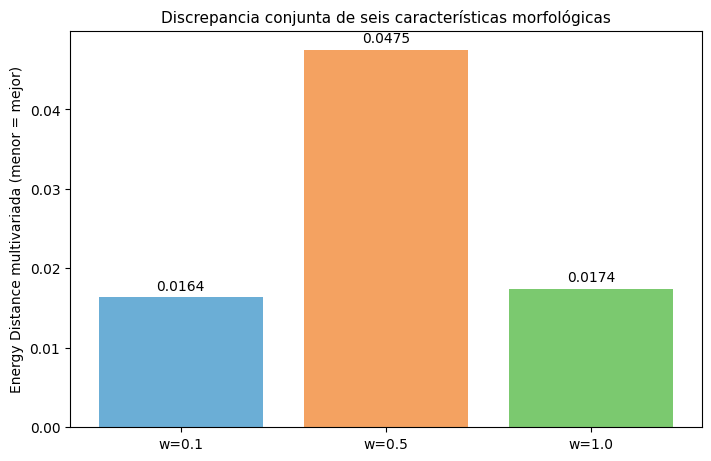

In [9]:
def weighted_cross_distance(x,y,wx,wy,chunk=384):
    """Media empírica ponderada de la distancia euclidiana entre X e Y."""
    total=0.0
    wx=np.asarray(wx,dtype=np.float64)
    wy=np.asarray(wy,dtype=np.float64)
    for i in range(0,len(x),chunk):
        xi=x[i:i+chunk]
        wi=wx[i:i+chunk]
        for j in range(0,len(y),chunk):
            yj=y[j:j+chunk]
            wj=wy[j:j+chunk]
            dist=cdist(xi,yj,metric='euclidean')
            total+=float(np.einsum('i,ij,j->',wi,dist,wj,optimize=True))
    return total


def weighted_within_distance(x,w,chunk=384):
    """Media dentro de una distribución, con pares (i,j) ordenados."""
    total=0.0
    w=np.asarray(w,dtype=np.float64)
    for i in range(0,len(x),chunk):
        xi=x[i:i+chunk]; wi=w[i:i+chunk]
        for j in range(i,len(x),chunk):
            xj=x[j:j+chunk]; wj=w[j:j+chunk]
            dist=cdist(xi,xj,metric='euclidean')
            value=float(np.einsum('i,ij,j->',wi,dist,wj,optimize=True))
            total += value if i==j else 2*value
    return total

zcols=[f+'_z' for f in FEATURES]
X=real_df[zcols].to_numpy(dtype=np.float64)
a=real_df['mix_weight'].to_numpy(dtype=np.float64)
rr=weighted_within_distance(X,a,chunk=CFG.ENERGY_CHUNK)
energy_rows=[]
for model in MODEL_LABELS:
    syn=synth_df.loc[synth_df.model==model]
    Y=syn[zcols].to_numpy(dtype=np.float64)
    b=syn['mix_weight'].to_numpy(dtype=np.float64)
    cross=weighted_cross_distance(X,Y,a,b,chunk=CFG.ENERGY_CHUNK)
    yy=weighted_within_distance(Y,b,chunk=CFG.ENERGY_CHUNK)
    raw=2*cross-rr-yy
    if raw < -1e-7:
        raise ArithmeticError(f'Energy negativa inesperada: {raw} ({model})')
    energy_rows.append({'model':model,'weight':float(model.split('=')[1]),
                        'energy_distance_multivariate':max(0.0,float(raw)),
                        'term_2_cross':2*cross,'term_real_real':rr,'term_synth_synth':yy,
                        'estimator':'weighted_empirical_V'})
energy_df=pd.DataFrame(energy_rows).sort_values('weight')
energy_df.to_csv(FOLDERS['energy']/'energy_global_resumen.csv',index=False)
display(energy_df[['model','energy_distance_multivariate']].round(6))

fig,ax=plt.subplots(figsize=(7,4.5),layout='constrained')
ax.bar(energy_df.model,energy_df.energy_distance_multivariate,
       color=[COLOR[m] for m in energy_df.model])
ax.set_ylabel('Energy Distance multivariada (menor = mejor)')
ax.set_title('Discrepancia conjunta de seis características morfológicas')
for i,v in enumerate(energy_df.energy_distance_multivariate):
    ax.annotate(f'{v:.4f}',(i,v),xytext=(0,5),textcoords='offset points',ha='center')
save_figure(fig,FOLDERS['energy'],'comparacion_energy')


## 9. Comparación por condición

Se calcula la distancia de Wasserstein separadamente para cada combinación de tipo de tumor y plano anatómico.

In [10]:
conditional_rows=[]
for model in MODEL_LABELS:
    syn=synth_df.loc[synth_df.model==model]
    for condition in CONDITIONS:
        r=real_df.loc[real_df.condition==condition]
        s=syn.loc[syn.condition==condition]
        for feature in FEATURES:
            key=feature+'_z'
            dist=wasserstein_distance(r[key].to_numpy(float),s[key].to_numpy(float))
            conditional_rows.append({'model':model,'weight':float(model.split('=')[1]),
                                      'condition':condition,'feature':feature,
                                      'wasserstein_1_standardized':float(dist),
                                      'n_real':len(r),'n_synth':len(s)})
conditional_detail=pd.DataFrame(conditional_rows)
conditional_mean=(conditional_detail.groupby(['model','weight','condition'],as_index=False)
                  ['wasserstein_1_standardized'].mean()
                  .rename(columns={'wasserstein_1_standardized':'wasserstein_mean_6_conditional'}))
conditional_detail.to_csv(FOLDERS['conditional']/'wasserstein_condicional_detalle.csv',index=False)
conditional_mean.to_csv(FOLDERS['conditional']/'wasserstein_por_condicion.csv',index=False)
display(conditional_mean.pivot(index='condition',columns='model',
                               values='wasserstein_mean_6_conditional').loc[CONDITIONS,MODEL_LABELS].round(5))


model,w=0.1,w=0.5,w=1.0
condition,,,
gl_ax,0.18606,0.18965,0.18730
gl_co,0.14184,0.21152,0.17543
gl_sa,0.16498,0.23700,0.15526
me_ax,0.19665,0.20196,0.16335
me_co,0.17796,0.10968,0.12163
me_sa,0.16373,0.15969,0.17134
pi_ax,0.12368,0.15446,0.09958
pi_co,0.09863,0.28015,0.12902
pi_sa,0.09422,0.20954,0.12072


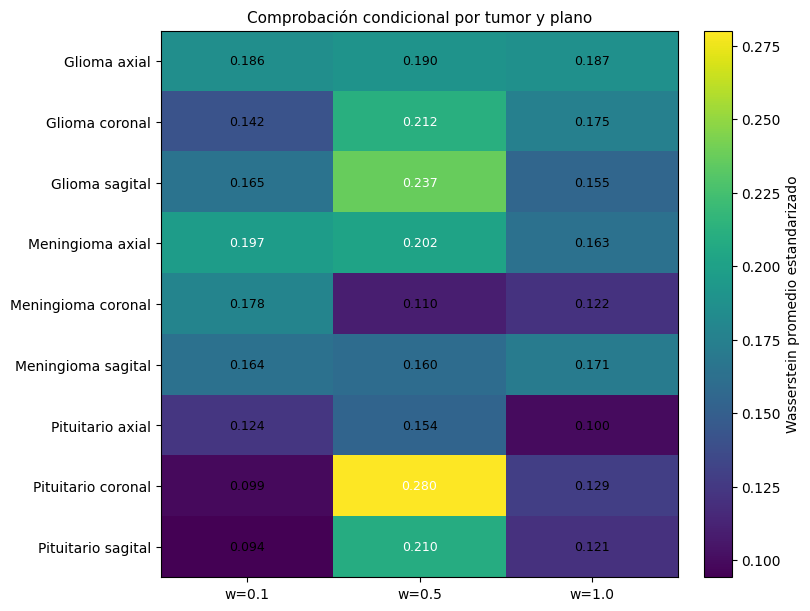

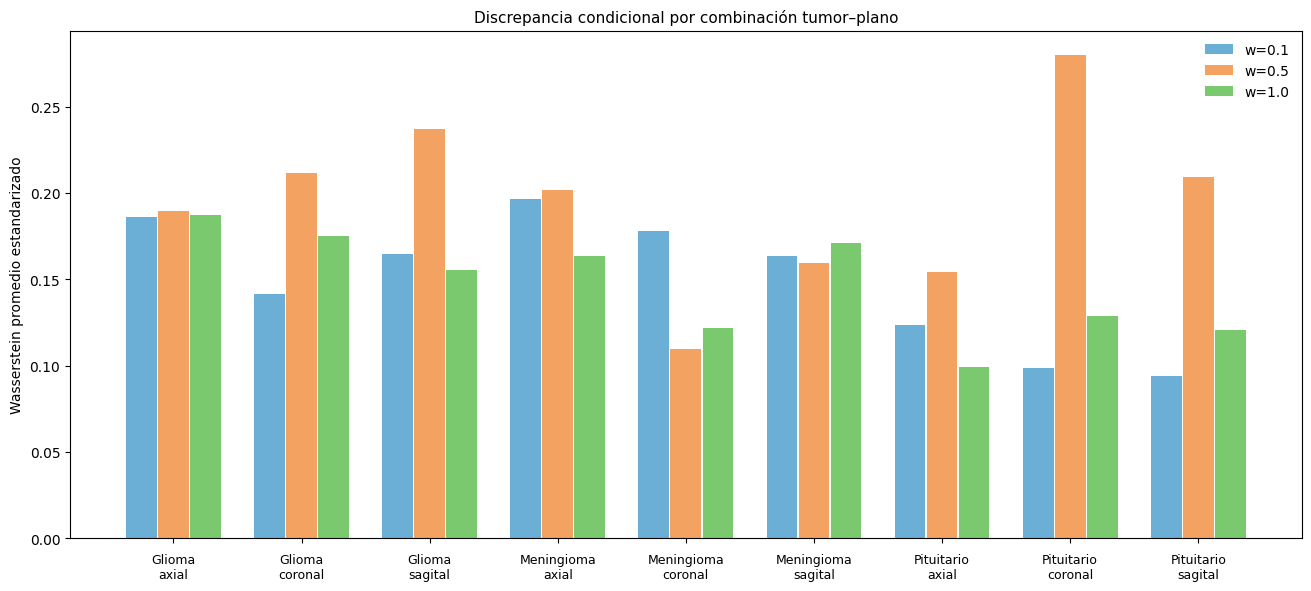

In [11]:
conditional_pivot=(conditional_mean.pivot(index='condition',columns='model',
                                         values='wasserstein_mean_6_conditional')
                   .loc[CONDITIONS,MODEL_LABELS])
fig,ax=plt.subplots(figsize=(8,6),layout='constrained')
image=ax.imshow(conditional_pivot.to_numpy(float),aspect='auto',cmap='viridis')
ax.set_xticks(np.arange(len(MODEL_LABELS)),MODEL_LABELS)
ax.set_yticks(np.arange(len(CONDITIONS)),[condition_label(c) for c in CONDITIONS])
for i in range(len(CONDITIONS)):
    for j in range(len(MODEL_LABELS)):
        value=conditional_pivot.iloc[i,j]
        ax.text(j,i,f'{value:.3f}',ha='center',va='center',fontsize=9,
                color='white' if (value-conditional_pivot.to_numpy().min()) /
                max(1e-9,np.ptp(conditional_pivot.to_numpy())) > .53 else 'black')
fig.colorbar(image,ax=ax,label='Wasserstein promedio estandarizado')
ax.set_title('Comprobación condicional por tumor y plano')
save_figure(fig,FOLDERS['conditional'],'mapa_calor_condiciones')

fig,ax=plt.subplots(figsize=(13,5.8),layout='constrained')
xx=np.arange(len(CONDITIONS))
for j,model in enumerate(MODEL_LABELS):
    ax.bar(xx+(j-1)*.25,conditional_pivot[model],width=.24,
           label=model,color=COLOR[model])
ax.set_xticks(xx,[condition_label(c, break_line=True) for c in CONDITIONS])
ax.tick_params(axis='x', labelsize=9, pad=7)
ax.set_ylabel('Wasserstein promedio estandarizado')
ax.set_title('Discrepancia condicional por combinación tumor–plano')
ax.legend(frameon=False)
save_figure(fig,FOLDERS['conditional'],'comparacion_por_condicion')


## 10. Tasas de aceptación morfológica

Se recuperan las tasas de aceptación y los motivos de rechazo registrados durante la generación.

In [12]:
qc_rows=[]
reason_rows=[]
consistency=[]
for model in MODEL_LABELS:
    data=QC_TABLES[model]
    summary=data['summary']
    needed={'condition','accepted','rejected','attempts'}
    if summary.empty or not needed.issubset(summary.columns):
        raise RuntimeError(f'Resumen QC incompleto para {model}: {data["root"]}')
    if summary['condition'].duplicated().any():
        raise RuntimeError(f'Condiciones QC duplicadas para {model}')
    if set(summary.condition)!=set(CONDITIONS):
        raise RuntimeError(f'Condiciones QC incompletas para {model}')
    for row in summary.itertuples(index=False):
        n_acc=int(row.accepted); n_rej=int(row.rejected); n_try=int(row.attempts)
        if n_acc+n_rej!=n_try:
            raise RuntimeError(f'Inconsistencia QC: {model} {row.condition}')
        in_manifest=int((data['accepted'].condition==row.condition).sum())
        if n_acc!=in_manifest:
            raise RuntimeError(f'Manifest/Resumen aceptadas no coincide: {model} {row.condition}')
        qc_rows.append({'model':model,'weight':float(model.split('=')[1]),
                        'condition':row.condition,'accepted':n_acc,'rejected':n_rej,
                        'attempts':n_try,'acceptance_rate':n_acc/n_try})
    attempt_df=data['attempts']
    if not attempt_df.empty:
        if 'condition' in attempt_df and len(attempt_df)!=int(summary['attempts'].sum()):
            raise RuntimeError(f'Intentos: total manifest vs summary no coincide ({model})')
    rejected=data['rejected']
    if not rejected.empty:
        if 'qc_reasons' not in rejected.columns:
            raise ValueError(f'Falta qc_reasons en manifest rechazadas de {model}')
        if len(rejected)!=int(summary['rejected'].sum()):
            raise RuntimeError(f'Rechazadas: total manifest vs summary no coincide ({model})')
        for r in rejected.itertuples(index=False):
            reasons=[reason.strip() for reason in str(r.qc_reasons).split('|') if reason.strip()]
            for reason in reasons:
                matched=re.match(r'^(area_fraction|centroid_x|centroid_y|bbox_w|bbox_h|n_components)',reason)
                category=matched.group(1) if matched else ('mascara_vacia' if 'vacía' in reason else 'otros')
                reason_rows.append({'model':model,'condition':r.condition,
                                    'feature_or_reason':category,'qc_reason_detail':reason})

qc_df=pd.DataFrame(qc_rows).sort_values(['weight','condition'])
qc_global=(qc_df.groupby(['model','weight'],as_index=False)[['accepted','rejected','attempts']].sum())
qc_global['acceptance_rate']=qc_global['accepted']/qc_global['attempts']
qc_df.to_csv(FOLDERS['qc']/'aceptacion_por_condicion.csv',index=False)
qc_global.to_csv(FOLDERS['qc']/'aceptacion_global.csv',index=False)

reason_detail=pd.DataFrame(reason_rows,columns=['model','condition','feature_or_reason','qc_reason_detail'])
reason_summary=(reason_detail.groupby(['model','feature_or_reason'],as_index=False)
                .size().rename(columns={'size':'n_apariciones'}))
reason_detail.to_csv(FOLDERS['qc']/'motivos_rechazo_detalle.csv',index=False)
reason_summary.to_csv(FOLDERS['qc']/'motivos_rechazo.csv',index=False)
display(qc_global)
display(reason_summary)


,model,weight,accepted,rejected,attempts,acceptance_rate
0,w=0.1,0.1,900,106,1006,0.894632
1,w=0.5,0.5,900,109,1009,0.891972
2,w=1.0,1.0,900,78,978,0.920245


,model,feature_or_reason,n_apariciones
0,w=0.1,area_fraction,8
1,w=0.1,bbox_h,28
2,w=0.1,bbox_w,21
3,w=0.1,centroid_x,30
4,w=0.1,centroid_y,30
5,w=0.1,mascara_vacia,13
6,w=0.1,n_components,3
7,w=0.5,area_fraction,9
8,w=0.5,bbox_h,21
9,w=0.5,bbox_w,22


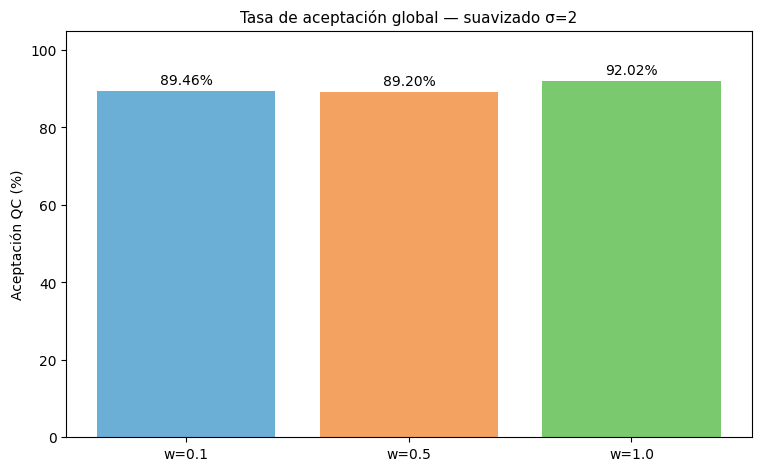

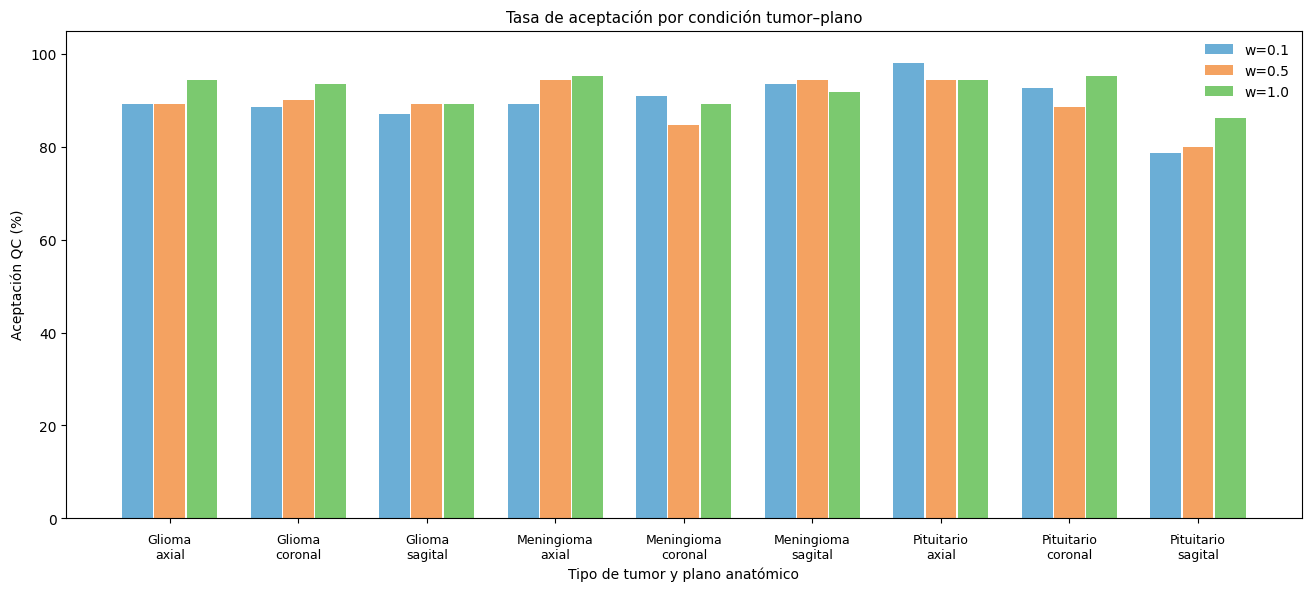

In [13]:
fig,ax=plt.subplots(figsize=(7.5,4.6),layout='constrained')
ax.bar(qc_global.model,100*qc_global.acceptance_rate,color=[COLOR[m] for m in qc_global.model])
ax.set_ylabel('Aceptación QC (%)')
ax.set_ylim(0,105)
ax.set_title('Tasa de aceptación global — suavizado σ=2')
for i,v in enumerate(100*qc_global.acceptance_rate):
    ax.annotate(f'{v:.2f}%',(i,v),xytext=(0,5),textcoords='offset points',ha='center')
save_figure(fig,FOLDERS['qc'],'comparacion_aceptacion')

qcp=qc_df.pivot(index='condition',columns='model',values='acceptance_rate').loc[CONDITIONS,MODEL_LABELS]
fig,ax=plt.subplots(figsize=(13,5.8),layout='constrained')
xx=np.arange(len(CONDITIONS))
for j,model in enumerate(MODEL_LABELS):
    ax.bar(xx+(j-1)*.25,100*qcp[model],width=.24,color=COLOR[model],label=model)
ax.set_xticks(xx, [condition_label(c, break_line=True) for c in CONDITIONS])
ax.tick_params(axis='x', labelsize=9, pad=7)
ax.set_ylabel('Aceptación QC (%)')
ax.set_ylim(0,105)
ax.set_title('Tasa de aceptación por condición tumor–plano')
ax.set_xlabel('Tipo de tumor y plano anatómico')
ax.legend(frameon=False)
save_figure(fig,FOLDERS['qc'],'aceptacion_por_condicion')


## 11. Contrastes distribucionales: Kolmogorov–Smirnov

Se contrasta la igualdad distribucional de las características continuas mediante permutaciones estratificadas por condición y ajuste de Holm. Los contrastes se consideran exploratorios por la selección morfológica previa.

In [14]:
# ============================================================
# PRUEBA KS GLOBAL PONDERADA POR CONDICIÓN, MEDIANTE PERMUTACIONES
# ============================================================

CONTINUOUS_FEATURES = [
    'area_fraction', 'centroid_x', 'centroid_y',
    'bbox_w', 'bbox_h',
]


def weighted_ks_statistic(sorted_delta, is_group_end):
    """D = sup |F_real(x)-F_sint(x)|, evaluado AL FINAL de cada empate."""
    cumulative = np.cumsum(sorted_delta, dtype=np.float64)
    return float(np.max(np.abs(cumulative[is_group_end])))


def run_stratified_weighted_ks(real, synth, feature, n_permutations, seed):
    """
    Estadístico KS sobre las mezclas globales EQUILIBRADAS P(c)=1/9.
    P-valor Monte Carlo: permutar las etiquetas real/sint dentro de
    cada condición, con los tamaños de cada condición fijos.

    Bajo H0, real y sint deben tener la misma distribución condicional
    por condición (hipótesis más fuerte que la igualdad de marginales).
    """
    if int(n_permutations) < 99:
        raise ValueError('Se requieren al menos 99 permutaciones.')
    if set(real.condition.unique()) != set(CONDITIONS):
        raise ValueError('Faltan condiciones en datos reales.')
    if set(synth.condition.unique()) != set(CONDITIONS):
        raise ValueError('Faltan condiciones en datos sintéticos.')

    rng = np.random.default_rng(seed)
    values_list = []
    observed_deltas = []
    strata = []
    offset = 0

    for condition in CONDITIONS:
        rv = real.loc[real.condition == condition, feature + '_z'].to_numpy(dtype=np.float64)
        sv = synth.loc[synth.condition == condition, feature + '_z'].to_numpy(dtype=np.float64)
        nr, ns = len(rv), len(sv)
        if nr < 2 or ns < 2:
            raise ValueError(f'Muestra insuficiente en {condition}: {nr} real, {ns} sintética.')
        if not (np.isfinite(rv).all() and np.isfinite(sv).all()):
            raise ValueError(f'Valor no finito en {condition} / {feature}.')

        values_list.extend([rv, sv])
        w_real = 1.0 / (len(CONDITIONS) * nr)
        w_synth = 1.0 / (len(CONDITIONS) * ns)
        observed_deltas.append(np.concatenate([
            np.full(nr, +w_real, dtype=np.float64),
            np.full(ns, -w_synth, dtype=np.float64),
        ]))
        strata.append((slice(offset, offset + nr + ns), nr, ns, w_real, w_synth))
        offset += nr + ns

    values = np.concatenate(values_list)
    delta_original = np.concatenate(observed_deltas)
    sorted_idx = np.argsort(values, kind='stable')
    ordered_values = values[sorted_idx]
    # La CDF salta en un valor único; NO evaluar dentro de valores empatados.
    is_group_end = np.r_[ordered_values[1:] != ordered_values[:-1], True]

    observed = weighted_ks_statistic(delta_original[sorted_idx], is_group_end)
    null_stats = np.empty(n_permutations, dtype=np.float64)
    permuted_delta = np.empty_like(delta_original)

    for perm in range(n_permutations):
        for idx_slice, nr, ns, w_real, w_synth in strata:
            labels = rng.permutation(nr + ns)
            local_weights = np.full(nr + ns, -w_synth, dtype=np.float64)
            local_weights[labels[:nr]] = +w_real
            permuted_delta[idx_slice] = local_weights
        null_stats[perm] = weighted_ks_statistic(
            permuted_delta[sorted_idx], is_group_end
        )

    p_value = float((1 + np.count_nonzero(null_stats >= observed - 1e-12)) /
                    (n_permutations + 1))
    return observed, p_value, null_stats


def adjust_pvalues(pvals, method='holm'):
    """Correcciones independientes de statsmodels: Holm y BH."""
    p = np.asarray(pvals, dtype=float)
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('p-valores fuera del intervalo [0,1].')
    n = len(p)
    order = np.argsort(p)
    sorted_p = p[order]
    if method == 'holm':
        adjusted = np.maximum.accumulate((n - np.arange(n)) * sorted_p)
    elif method == 'bh':
        adjusted = np.minimum.accumulate(
            (n / (np.arange(n) + 1) * sorted_p)[::-1]
        )[::-1]
    else:
        raise ValueError(f'Método desconocido: {method}')
    result = np.empty(n, dtype=float)
    result[order] = np.clip(adjusted, 0, 1)
    return result


if CFG.KS_N_PERMUTATIONS < 99:
    raise ValueError('CFG.KS_N_PERMUTATIONS debe ser >=99.')

ks_results = []
ks_null_rows = []

for midx, model in enumerate(MODEL_LABELS):
    syn = synth_df.loc[synth_df.model == model]
    for fidx, feature in enumerate(CONTINUOUS_FEATURES):
        observed, p_raw, perm_values = run_stratified_weighted_ks(
            real_df,
            syn,
            feature,
            n_permutations=CFG.KS_N_PERMUTATIONS,
            seed=CFG.RANDOM_SEED + 1000 * midx + 31 * fidx,
        )
        ks_results.append({
            'model': model,
            'weight': float(model.split('=')[1]),
            'feature': feature,
            'feature_name': FEATURE_NAMES[feature],
            'ks_D_weighted': observed,
            'p_permutation_raw': p_raw,
            'n_real': len(real_df),
            'n_synth': len(syn),
            'n_conditions': len(CONDITIONS),
            'n_permutations': CFG.KS_N_PERMUTATIONS,
            'ks_null_q95': float(np.quantile(perm_values, 0.95)),
            'ks_null_q99': float(np.quantile(perm_values, 0.99)),
            'ks_null_mean': float(np.mean(perm_values)),
        })
        ks_null_rows.extend({
            'model': model, 'feature': feature,
            'permutation': i + 1, 'ks_D_null': float(v),
        } for i, v in enumerate(perm_values))
        print(f'{model:6s} | {feature:16s} | D={observed:.5f} | p={p_raw:.5f}')

ks_df = pd.DataFrame(ks_results)
ks_df['p_holm_15'] = adjust_pvalues(ks_df['p_permutation_raw'], 'holm')
ks_df['q_bh_15'] = adjust_pvalues(ks_df['p_permutation_raw'], 'bh')
ks_df['reject_holm_005'] = ks_df['p_holm_15'] < CFG.KS_ALPHA
ks_df['reject_bh_005'] = ks_df['q_bh_15'] < CFG.KS_ALPHA

# W1 ya calculada: se reporta junto a D y p para distinguir magnitud y evidencia.
ks_df = ks_df.merge(
    wasserstein_df[['model', 'feature', 'wasserstein_1_standardized']],
    on=['model', 'feature'], how='left', validate='one_to_one'
)

ks_df.to_csv(FOLDERS['tests'] / 'ks_global_cinco_caracteristicas.csv', index=False)
pd.DataFrame(ks_null_rows).to_csv(
    FOLDERS['tests'] / 'ks_distribucion_nula_permutaciones.csv', index=False
)

ks_summary = ks_df.groupby(['model', 'weight'], as_index=False).agg(
    n_pruebas=('feature', 'size'),
    n_rechazos_holm=('reject_holm_005', 'sum'),
    n_rechazos_bh=('reject_bh_005', 'sum'),
    ks_D_medio=('ks_D_weighted', 'mean'),
    ks_D_maximo=('ks_D_weighted', 'max'),
    p_holm_minimo=('p_holm_15', 'min'),
)
ks_summary.to_csv(FOLDERS['tests'] / 'ks_resumen_por_modelo.csv', index=False)

display(ks_df[['model', 'feature', 'ks_D_weighted', 'p_permutation_raw',
               'p_holm_15', 'q_bh_15', 'reject_holm_005',
               'wasserstein_1_standardized']].round(5))
display(ks_summary.round(5))


w=0.1  | area_fraction    | D=0.07758 | p=0.00200
w=0.1  | centroid_x       | D=0.03767 | p=0.21200
w=0.1  | centroid_y       | D=0.04329 | p=0.05900
w=0.1  | bbox_w           | D=0.05149 | p=0.03200
w=0.1  | bbox_h           | D=0.07244 | p=0.00100
w=0.5  | area_fraction    | D=0.09614 | p=0.00100
w=0.5  | centroid_x       | D=0.02956 | p=0.48900
w=0.5  | centroid_y       | D=0.03249 | p=0.31900
w=0.5  | bbox_w           | D=0.11068 | p=0.00100
w=0.5  | bbox_h           | D=0.11452 | p=0.00100
w=1.0  | area_fraction    | D=0.06885 | p=0.00200
w=1.0  | centroid_x       | D=0.03865 | p=0.20200
w=1.0  | centroid_y       | D=0.04212 | p=0.07900
w=1.0  | bbox_w           | D=0.06861 | p=0.00100
w=1.0  | bbox_h           | D=0.08143 | p=0.00100


,model,feature,ks_D_weighted,p_permutation_raw,p_holm_15,q_bh_15,reject_holm_005,wasserstein_1_standardized
0,w=0.1,area_fraction,0.07758,0.002,0.018,0.00375,True,0.14438
1,w=0.1,centroid_x,0.03767,0.212,0.808,0.24462,False,0.05175
2,w=0.1,centroid_y,0.04329,0.059,0.354,0.08850,False,0.07826
3,w=0.1,bbox_w,0.05149,0.032,0.224,0.05333,False,0.11021
4,w=0.1,bbox_h,0.07244,0.001,0.015,0.00250,True,0.12263
5,w=0.5,area_fraction,0.09614,0.001,0.015,0.00250,True,0.15690
6,w=0.5,centroid_x,0.02956,0.489,0.808,0.48900,False,0.03905
7,w=0.5,centroid_y,0.03249,0.319,0.808,0.34179,False,0.04428
8,w=0.5,bbox_w,0.11068,0.001,0.015,0.00250,True,0.16006
9,w=0.5,bbox_h,0.11452,0.001,0.015,0.00250,True,0.18523


,model,weight,n_pruebas,n_rechazos_holm,n_rechazos_bh,ks_D_medio,ks_D_maximo,p_holm_minimo
0,w=0.1,0.1,5,2,2,0.05649,0.07758,0.015
1,w=0.5,0.5,5,3,3,0.07668,0.11452,0.015
2,w=1.0,1.0,5,3,3,0.05993,0.08143,0.015


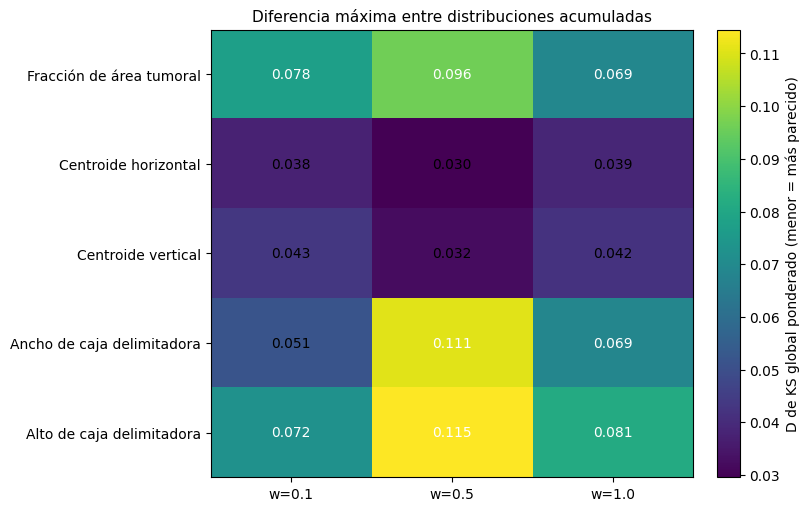

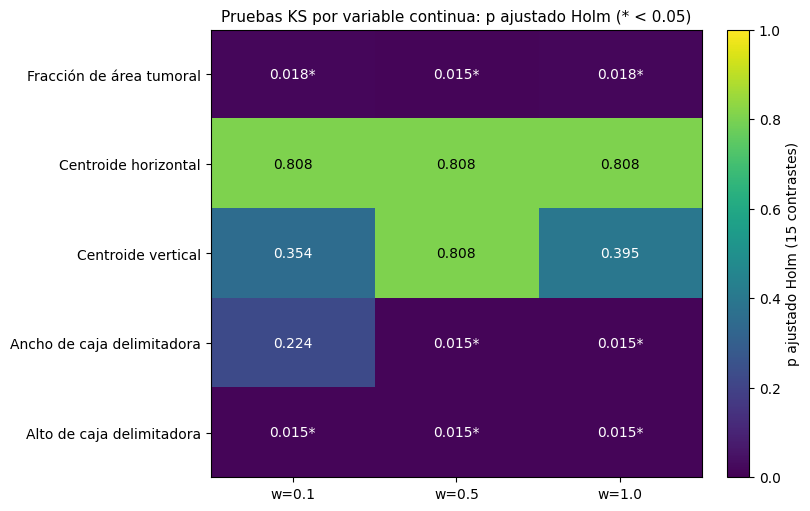

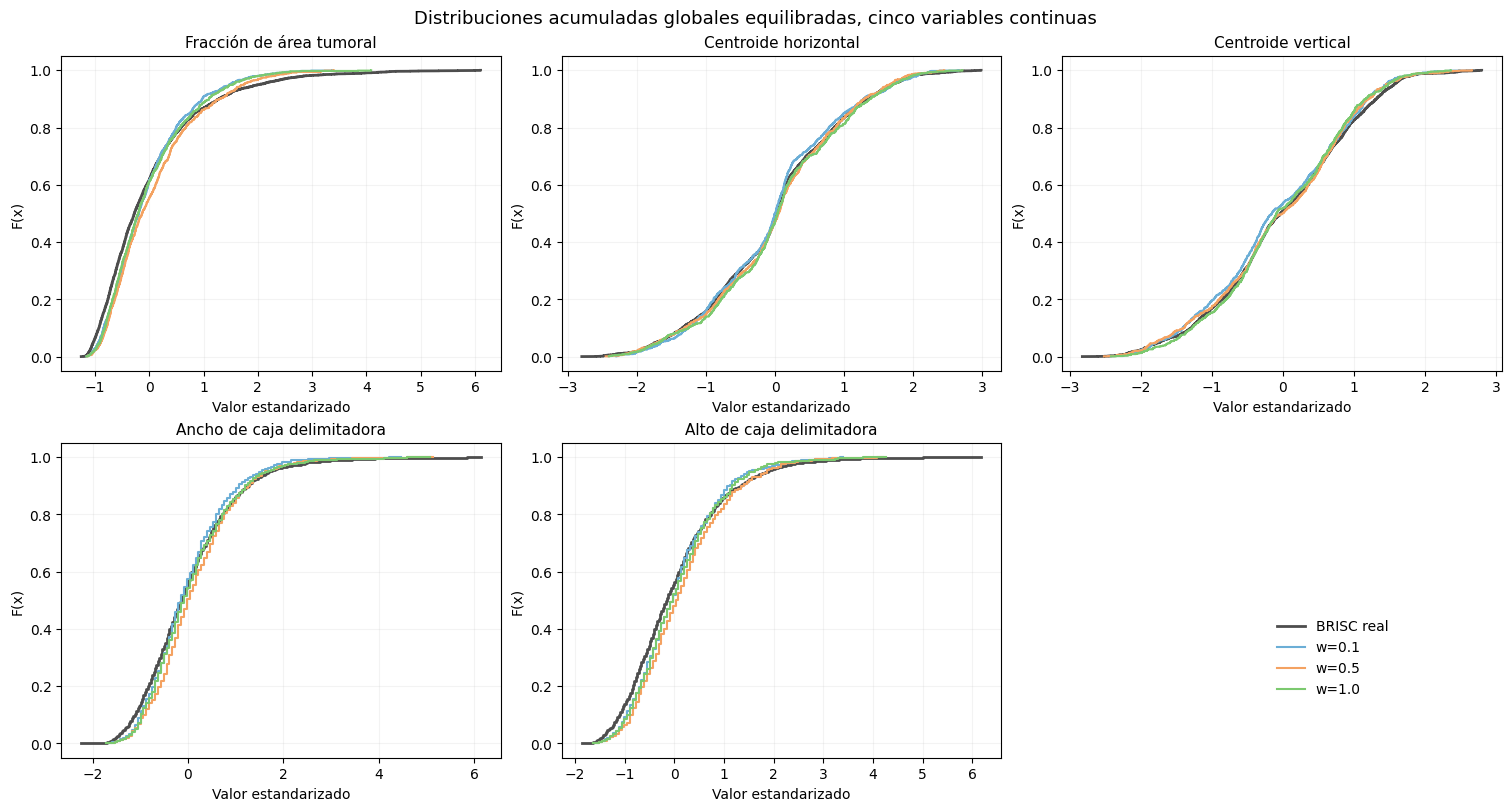

In [15]:
# ============================================================
# GRÁFICOS DE KS Y DISTRIBUCIONES ACUMULADAS PONDERADAS
# ============================================================

# Mapa de calor de D_KS (magnitud, no p-valor)
ks_pivot = ks_df.pivot(index='feature', columns='model', values='ks_D_weighted')
ks_pivot = ks_pivot.loc[CONTINUOUS_FEATURES, MODEL_LABELS]
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
im = ax.imshow(ks_pivot.to_numpy(), cmap='viridis', aspect='auto')
ax.set_xticks(range(len(MODEL_LABELS)), MODEL_LABELS)
ax.set_yticks(range(len(CONTINUOUS_FEATURES)),
              [FEATURE_NAMES[f] for f in CONTINUOUS_FEATURES])
for i, feature in enumerate(CONTINUOUS_FEATURES):
    for j, model in enumerate(MODEL_LABELS):
        val = ks_pivot.loc[feature, model]
        ax.text(j, i, f'{val:.3f}', ha='center', va='center',
                color='white' if val > 0.5 * np.nanmax(ks_pivot.to_numpy()) else 'black')
fig.colorbar(im, ax=ax, label='D de KS global ponderado (menor = más parecido)')
ax.set_title('Diferencia máxima entre distribuciones acumuladas')
save_figure(fig, FOLDERS['tests'], 'ks_mapa_calor_D')

# Mapa de calor de p-valores ajustados por Holm
p_pivot = ks_df.pivot(index='feature', columns='model', values='p_holm_15')
p_pivot = p_pivot.loc[CONTINUOUS_FEATURES, MODEL_LABELS]
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
im = ax.imshow(p_pivot.to_numpy(), cmap='viridis', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(MODEL_LABELS)), MODEL_LABELS)
ax.set_yticks(range(len(CONTINUOUS_FEATURES)),
              [FEATURE_NAMES[f] for f in CONTINUOUS_FEATURES])
for i, feature in enumerate(CONTINUOUS_FEATURES):
    for j, model in enumerate(MODEL_LABELS):
        value = p_pivot.loc[feature, model]
        ax.text(j, i, f'{value:.3f}' + ('*' if value < CFG.KS_ALPHA else ''),
                ha='center', va='center', color='white' if value < 0.4 else 'black')
fig.colorbar(im, ax=ax, label='p ajustado Holm (15 contrastes)')
ax.set_title('Pruebas KS por variable continua: p ajustado Holm (* < 0.05)')
save_figure(fig, FOLDERS['tests'], 'ks_mapa_calor_p_holm')


def weighted_ecdf(values, weights):
    values = np.asarray(values, dtype=np.float64)
    weights = np.asarray(weights, dtype=np.float64)
    ind = np.argsort(values, kind='stable')
    val, wei = values[ind], weights[ind]
    ends = np.r_[val[1:] != val[:-1], True]
    return val[ends], (np.cumsum(wei) / wei.sum())[ends]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for ax, feature in zip(axes.flat, CONTINUOUS_FEATURES):
    key = feature + '_z'
    xr, cr = weighted_ecdf(real_df[key], real_df['mix_weight'])
    ax.step(xr, cr, where='post', label='BRISC real', linewidth=2.0,
            color=COLOR['BRISC real'])
    for model in MODEL_LABELS:
        syn = synth_df.loc[synth_df.model == model]
        xs, cs = weighted_ecdf(syn[key], syn['mix_weight'])
        ax.step(xs, cs, where='post', label=model, linewidth=1.5, color=COLOR[model])
    ax.set_title(FEATURE_NAMES[feature])
    ax.set_xlabel('Valor estandarizado')
    ax.set_ylabel('F(x)')
    ax.grid(alpha=.15)
axes.flat[-1].axis('off')
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower right', bbox_to_anchor=(.93,.12), frameon=False)
fig.suptitle('Distribuciones acumuladas globales equilibradas, cinco variables continuas', fontsize=13)
save_figure(fig, FOLDERS['tests'], 'ks_funciones_distribucion_acumuladas')


### 11.1 Contraste de Cramér–von Mises

Se compara la discrepancia integrada entre las funciones de distribución empíricas ponderadas, utilizando permutaciones estratificadas y un ajuste conjunto de Holm.

In [16]:
# ============================================================
# CvM GLOBAL PONDERADO CON PERMUTACIONES ESTRATIFICADAS
# ============================================================


def weighted_cvm_statistic(sorted_signed_weights, is_group_end):
    """Integral de (F_real - F_sint)^2 respecto de H=(F_real+F_sint)/2.

    sorted_signed_weights: +1/(9*n_real_cond) para reales, negativo para sinteticas.
    Se evalua la diferencia de CDF DESPUES del salto de cada valor empatado.
    Las masas de H se recalculan por permutacion (importante si nr != ns).
    """
    differences = np.cumsum(sorted_signed_weights, dtype=np.float64)[is_group_end]
    pooled_cumulative = np.cumsum(
        0.5 * np.abs(sorted_signed_weights), dtype=np.float64
    )[is_group_end]
    dH = np.diff(np.r_[0.0, pooled_cumulative])
    return float(np.dot(differences ** 2, dH))


def run_stratified_weighted_cvm(real, synth, feature, n_permutations, seed):
    """CvM ponderado de mezclas marginales globales, permutando dentro de condicion.

    H0 para la calibracion: intercambiabilidad real/sintetica DENTRO DE
    CADA condicion, no solo igualdad de las marginales agregadas.
    """
    if int(n_permutations) < 99:
        raise ValueError('CVM_N_PERMUTATIONS debe ser al menos 99.')
    if set(real.condition.unique()) != set(CONDITIONS) or set(synth.condition.unique()) != set(CONDITIONS):
        raise ValueError('Se requieren las nueve condiciones en ambas muestras.')

    rng = np.random.default_rng(seed)
    values_parts = []
    signed_parts = []
    strata = []
    offset = 0

    for condition in CONDITIONS:
        rv = real.loc[real.condition == condition, feature + '_z'].to_numpy(dtype=np.float64)
        sv = synth.loc[synth.condition == condition, feature + '_z'].to_numpy(dtype=np.float64)
        nr, ns = len(rv), len(sv)
        if nr < 2 or ns < 2 or not np.isfinite(rv).all() or not np.isfinite(sv).all():
            raise ValueError(f'Datos insuficientes/no finitos en {condition}/{feature}.')
        w_real = 1.0 / (len(CONDITIONS) * nr)
        w_synth = 1.0 / (len(CONDITIONS) * ns)
        values_parts.append(np.concatenate([rv, sv]))
        signed_parts.append(np.concatenate([
            np.full(nr, w_real, dtype=np.float64),
            np.full(ns, -w_synth, dtype=np.float64),
        ]))
        strata.append((slice(offset, offset + nr + ns), nr, ns, w_real, w_synth))
        offset += nr + ns

    pooled_values = np.concatenate(values_parts)
    delta_original = np.concatenate(signed_parts)
    order = np.argsort(pooled_values, kind='stable')
    sorted_values = pooled_values[order]
    group_ends = np.r_[sorted_values[1:] != sorted_values[:-1], True]
    observed = weighted_cvm_statistic(delta_original[order], group_ends)

    null_stats = np.empty(n_permutations, dtype=np.float64)
    permuted_delta = np.empty_like(delta_original)

    for perm in range(n_permutations):
        for idx_slice, nr, ns, wr, ws in strata:
            assignment = rng.permutation(nr + ns)
            local = np.full(nr + ns, -ws, dtype=np.float64)
            local[assignment[:nr]] = wr
            permuted_delta[idx_slice] = local
        null_stats[perm] = weighted_cvm_statistic(permuted_delta[order], group_ends)

    p_value = float(
        (1 + np.count_nonzero(null_stats >= observed - 1e-15))
        / (n_permutations + 1)
    )
    return observed, p_value, null_stats


cvm_rows = []
cvm_null_rows = []

for midx, model in enumerate(MODEL_LABELS):
    syn = synth_df.loc[synth_df.model == model]
    for fidx, feature in enumerate(CONTINUOUS_FEATURES):
        observed, p_raw, permutation_stats = run_stratified_weighted_cvm(
            real_df, syn, feature,
            n_permutations=CFG.CVM_N_PERMUTATIONS,
            seed=CFG.RANDOM_SEED + 1000 * midx + 31 * fidx,
        )
        cvm_rows.append({
            'model': model,
            'weight': float(model.split('=')[1]),
            'feature': feature,
            'feature_name': FEATURE_NAMES[feature],
            'cvm_T_weighted': observed,
            'p_permutation_raw': p_raw,
            'n_real': len(real_df),
            'n_synth': len(syn),
            'n_conditions': len(CONDITIONS),
            'n_permutations': CFG.CVM_N_PERMUTATIONS,
            'cvm_null_q95': float(np.quantile(permutation_stats, .95)),
            'cvm_null_q99': float(np.quantile(permutation_stats, .99)),
            'cvm_null_mean': float(np.mean(permutation_stats)),
        })
        cvm_null_rows.extend({
            'model': model, 'feature': feature,
            'permutation': i + 1, 'cvm_T_null': float(v),
        } for i, v in enumerate(permutation_stats))
        print(f'{model:6s} | {feature:16s} | CvM={observed:.6f} | p={p_raw:.5f}')

cvm_df = pd.DataFrame(cvm_rows)
cvm_df['p_holm_15'] = adjust_pvalues(cvm_df['p_permutation_raw'], 'holm')
cvm_df['q_bh_15'] = adjust_pvalues(cvm_df['p_permutation_raw'], 'bh')
cvm_df['reject_holm_005'] = cvm_df['p_holm_15'] < CFG.CVM_ALPHA
cvm_df['reject_bh_005'] = cvm_df['q_bh_15'] < CFG.CVM_ALPHA
cvm_df = cvm_df.merge(
    wasserstein_df[['model','feature','wasserstein_1_standardized']],
    on=['model','feature'], how='left', validate='one_to_one'
)

# Holm conjunto sobre LOS 30 contrastes de KS + CvM, sin presuponer
# independencia entre las pruebas. Se conserva tambien Holm15 por separado.
combined_pvals = np.r_[
    ks_df['p_permutation_raw'].to_numpy(float),
    cvm_df['p_permutation_raw'].to_numpy(float),
]
combined_holm = adjust_pvalues(combined_pvals, 'holm')
n_ks = len(ks_df)
ks_df['p_holm_30'] = combined_holm[:n_ks]
cvm_df['p_holm_30'] = combined_holm[n_ks:]
ks_df['reject_holm_30_005'] = ks_df['p_holm_30'] < CFG.KS_ALPHA
cvm_df['reject_holm_30_005'] = cvm_df['p_holm_30'] < CFG.CVM_ALPHA

# Actualizacion del CSV KS con columnas adicionales: NO se eliminan
# columnas ni se reemplazan los anteriores estadisticos/p-valores.
ks_df.to_csv(FOLDERS['tests'] / 'ks_global_cinco_caracteristicas.csv', index=False)
cvm_df.to_csv(FOLDERS['tests'] / 'cvm_global_cinco_caracteristicas.csv', index=False)
pd.DataFrame(cvm_null_rows).to_csv(
    FOLDERS['tests'] / 'cvm_distribucion_nula_permutaciones.csv', index=False
)

cvm_summary = cvm_df.groupby(['model', 'weight'], as_index=False).agg(
    n_pruebas=('feature', 'size'),
    n_rechazos_holm_15=('reject_holm_005', 'sum'),
    n_rechazos_holm_30=('reject_holm_30_005', 'sum'),
    n_rechazos_bh_15=('reject_bh_005', 'sum'),
    cvm_T_medio=('cvm_T_weighted', 'mean'),
    cvm_T_maximo=('cvm_T_weighted', 'max'),
    p_holm_30_minimo=('p_holm_30', 'min'),
)
cvm_summary.to_csv(FOLDERS['tests'] / 'cvm_resumen_por_modelo.csv', index=False)

# Tabla conjunta por modelo y característica para comparar ambas pruebas.
tests_comparison = ks_df[[
    'model', 'weight', 'feature', 'feature_name', 'ks_D_weighted',
    'p_permutation_raw', 'p_holm_15', 'p_holm_30',
    'wasserstein_1_standardized',
]].rename(columns={
    'p_permutation_raw': 'ks_p_raw',
    'p_holm_15': 'ks_p_holm_15',
    'p_holm_30': 'ks_p_holm_30',
}).merge(
    cvm_df[[
        'model', 'feature', 'cvm_T_weighted', 'p_permutation_raw',
        'p_holm_15', 'p_holm_30',
    ]].rename(columns={
        'p_permutation_raw': 'cvm_p_raw',
        'p_holm_15': 'cvm_p_holm_15',
        'p_holm_30': 'cvm_p_holm_30',
    }),
    on=['model','feature'], validate='one_to_one',
)
tests_comparison.to_csv(
    FOLDERS['tests'] / 'comparacion_ks_cvm_por_variable.csv', index=False
)

# Se actualiza el resumen KS para incluir, ademas, el control de 30 pruebas.
ks_summary = ks_summary.merge(
    ks_df.groupby('model', as_index=False).agg(
        n_rechazos_holm_30=('reject_holm_30_005', 'sum'),
        p_holm_30_minimo=('p_holm_30', 'min'),
    ), on='model', validate='one_to_one'
)
ks_summary.to_csv(FOLDERS['tests'] / 'ks_resumen_por_modelo.csv', index=False)

display(cvm_df[[
    'model','feature','cvm_T_weighted','p_permutation_raw',
    'p_holm_15','p_holm_30','reject_holm_30_005',
    'wasserstein_1_standardized'
]].round(6))
display(cvm_summary.round(6))


w=0.1  | area_fraction    | CvM=0.001878 | p=0.00100
w=0.1  | centroid_x       | CvM=0.000240 | p=0.29400
w=0.1  | centroid_y       | CvM=0.000554 | p=0.02600
w=0.1  | bbox_w           | CvM=0.000759 | p=0.02700
w=0.1  | bbox_h           | CvM=0.001460 | p=0.00200
w=0.5  | area_fraction    | CvM=0.003891 | p=0.00100
w=0.5  | centroid_x       | CvM=0.000164 | p=0.46100
w=0.5  | centroid_y       | CvM=0.000177 | p=0.35100
w=0.5  | bbox_w           | CvM=0.003643 | p=0.00100
w=0.5  | bbox_h           | CvM=0.004705 | p=0.00100
w=1.0  | area_fraction    | CvM=0.001614 | p=0.00200
w=1.0  | centroid_x       | CvM=0.000261 | p=0.27700
w=1.0  | centroid_y       | CvM=0.000255 | p=0.20700
w=1.0  | bbox_w           | CvM=0.000954 | p=0.00500
w=1.0  | bbox_h           | CvM=0.001764 | p=0.00200


,model,feature,cvm_T_weighted,p_permutation_raw,p_holm_15,p_holm_30,reject_holm_30_005,wasserstein_1_standardized
0,w=0.1,area_fraction,0.001878,0.001,0.015,0.030,True,0.144380
1,w=0.1,centroid_x,0.000240,0.294,1.000,1.000,False,0.051748
2,w=0.1,centroid_y,0.000554,0.026,0.182,0.364,False,0.078256
3,w=0.1,bbox_w,0.000759,0.027,0.182,0.364,False,0.110206
4,w=0.1,bbox_h,0.001460,0.002,0.022,0.040,True,0.122626
5,w=0.5,area_fraction,0.003891,0.001,0.015,0.030,True,0.156901
6,w=0.5,centroid_x,0.000164,0.461,1.000,1.000,False,0.039052
7,w=0.5,centroid_y,0.000177,0.351,1.000,1.000,False,0.044278
8,w=0.5,bbox_w,0.003643,0.001,0.015,0.030,True,0.160065
9,w=0.5,bbox_h,0.004705,0.001,0.015,0.030,True,0.185229


,model,weight,n_pruebas,n_rechazos_holm_15,n_rechazos_holm_30,n_rechazos_bh_15,cvm_T_medio,cvm_T_maximo,p_holm_30_minimo
0,w=0.1,0.1,5,2,2,4,0.000978,0.001878,0.03
1,w=0.5,0.5,5,3,3,3,0.002516,0.004705,0.03
2,w=1.0,1.0,5,3,2,3,0.000970,0.001764,0.04


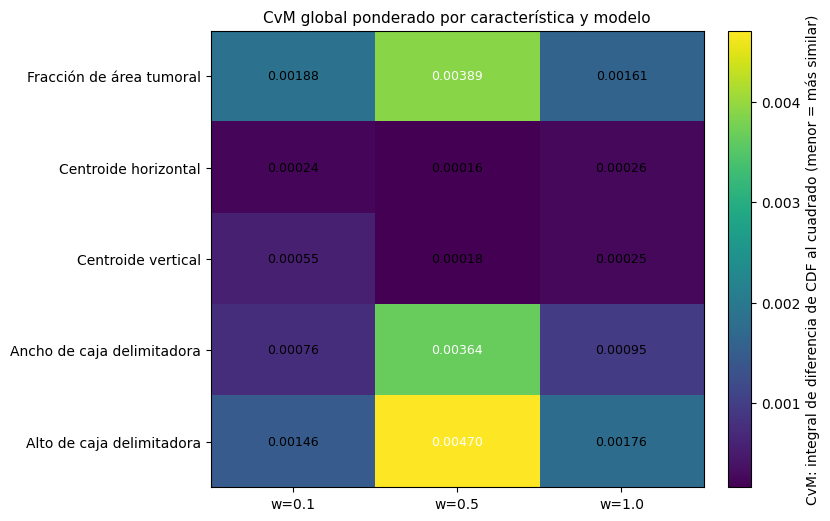

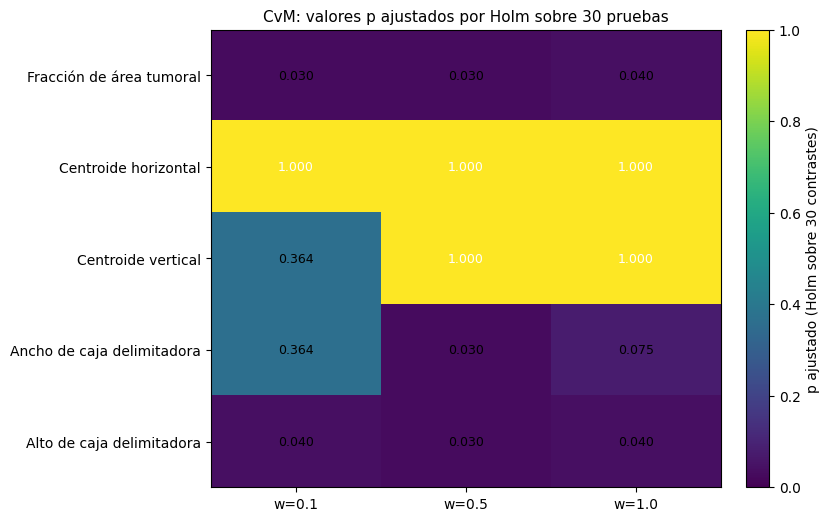

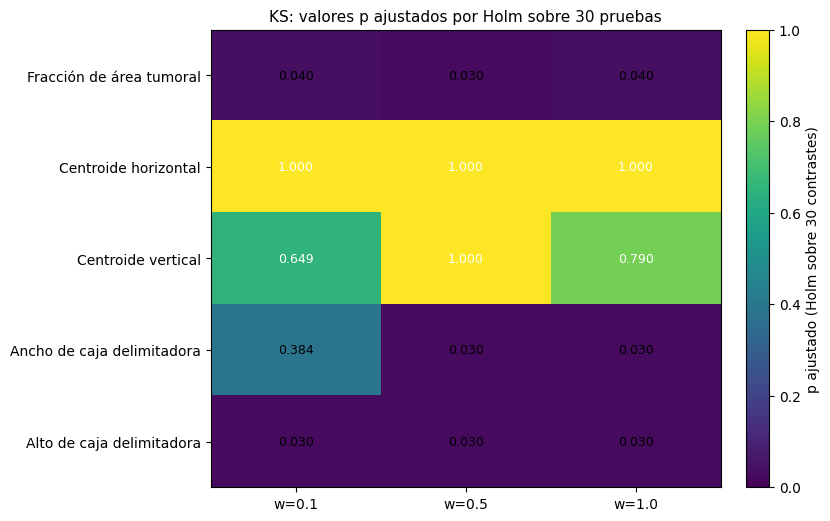

,model,ks_rechazos_30,cvm_rechazos_30
0,w=0.1,2,2
1,w=0.5,3,3
2,w=1.0,3,2


In [17]:
# ============================================================
# FIGURAS CvM Y COMPARACION DE VALORES P (HOLM CONJUNTO)
# ============================================================

def heatmap_test(df, value_col, title, stem, colorbar_text, vmin=None, vmax=None, fmt='.4f'):
    pivot = df.pivot(index='feature', columns='model', values=value_col)
    pivot = pivot.loc[CONTINUOUS_FEATURES, MODEL_LABELS]
    values = pivot.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(8.2, 5.1), layout='constrained')
    im = ax.imshow(values, cmap='viridis', vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_xticks(range(len(MODEL_LABELS)), MODEL_LABELS)
    ax.set_yticks(range(len(CONTINUOUS_FEATURES)),
                  [FEATURE_NAMES[f] for f in CONTINUOUS_FEATURES])
    center = (np.nanmax(values) + np.nanmin(values)) / 2
    for i in range(len(CONTINUOUS_FEATURES)):
        for j in range(len(MODEL_LABELS)):
            v = values[i, j]
            ax.text(j, i, format(v, fmt), ha='center', va='center',
                    color='white' if v > center else 'black', fontsize=9)
    fig.colorbar(im, ax=ax, label=colorbar_text)
    ax.set_title(title)
    save_figure(fig, FOLDERS['tests'], stem)


heatmap_test(
    cvm_df, 'cvm_T_weighted',
    'CvM global ponderado por característica y modelo',
    'cvm_mapa_calor_estadistico',
    'CvM: integral de diferencia de CDF al cuadrado (menor = más similar)',
    fmt='.5f',
)
heatmap_test(
    cvm_df, 'p_holm_30',
    'CvM: valores p ajustados por Holm sobre 30 pruebas',
    'cvm_mapa_calor_p_holm_30',
    'p ajustado (Holm sobre 30 contrastes)',
    vmin=0, vmax=1, fmt='.3f',
)
heatmap_test(
    ks_df, 'p_holm_30',
    'KS: valores p ajustados por Holm sobre 30 pruebas',
    'ks_mapa_calor_p_holm_30',
    'p ajustado (Holm sobre 30 contrastes)',
    vmin=0, vmax=1, fmt='.3f',
)

# Resumen conjunto de contrastes; no utilizar el número de rechazos
# como medida de proximidad para seleccionar el modelo.
combined_rejections = (
    tests_comparison.groupby('model', as_index=False)
    .agg(
        ks_rechazos_30=('ks_p_holm_30', lambda s: int((s < CFG.KS_ALPHA).sum())),
        cvm_rechazos_30=('cvm_p_holm_30', lambda s: int((s < CFG.CVM_ALPHA).sum())),
    )
)
combined_rejections.to_csv(
    FOLDERS['tests'] / 'resumen_conjunto_ks_cvm.csv', index=False
)
display(combined_rejections)


## 12. Tablas de comparación y registro reproducible

Se reúnen las métricas y se guardan los parámetros y archivos del análisis comparativo.

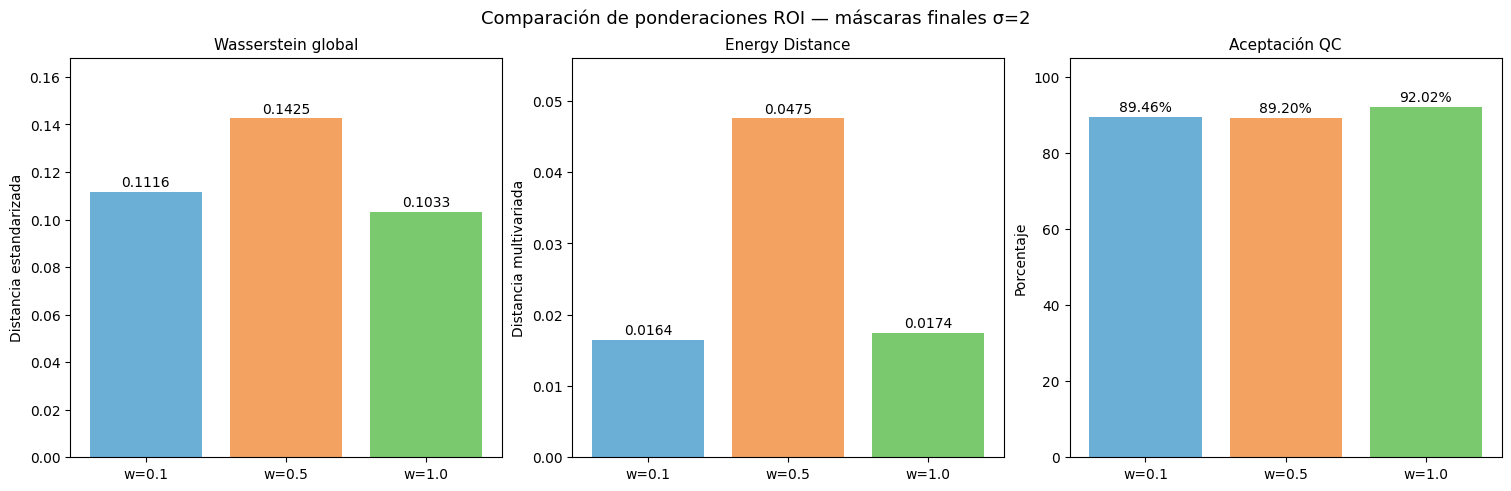

,model,weight,wasserstein_global_mean_6,rank_wasserstein_global,energy_distance_multivariate,accepted,rejected,attempts,acceptance_rate,wasserstein_conditional_mean_9,wasserstein_conditional_max_9,worst_condition,n_rechazos_holm,ks_D_medio,ks_D_maximo,cvm_n_rechazos_holm_15,cvm_n_rechazos_holm_30,cvm_T_medio,cvm_T_maximo,ks_n_rechazos_holm_30
0,w=0.1,0.1,0.111589,2,0.016410,900,106,1006,0.894632,0.149750,0.196646,me_ax,2,0.056494,0.077581,2,2,0.000978,0.001878,2
1,w=0.5,0.5,0.142514,3,0.047525,900,109,1009,0.891972,0.194849,0.280150,pi_co,3,0.076676,0.114518,3,3,0.002516,0.004705,3
2,w=1.0,1.0,0.103299,1,0.017439,900,78,978,0.920245,0.147069,0.187296,gl_ax,3,0.059932,0.081433,3,2,0.000970,0.001764,3


In [18]:
# 10.1 Síntesis global y rankings meramente descriptivos
summary=(w_global[['model','weight','wasserstein_global_mean_6','rank_wasserstein_global']]
         .merge(energy_df[['model','energy_distance_multivariate']],on='model')
         .merge(qc_global[['model','accepted','rejected','attempts','acceptance_rate']],on='model'))
conditional_agg=conditional_mean.groupby('model',as_index=False).agg(
    wasserstein_conditional_mean_9=('wasserstein_mean_6_conditional','mean'),
    wasserstein_conditional_max_9=('wasserstein_mean_6_conditional','max'),
    condition_worst=('condition', lambda s: s.iloc[0])
)
# La condición peor se identifica por máximo valor (no por orden en el dataframe).
worst=(conditional_mean.loc[conditional_mean.groupby('model')['wasserstein_mean_6_conditional'].idxmax(),
                            ['model','condition']].rename(columns={'condition':'worst_condition'}))
conditional_agg=conditional_agg.drop(columns=['condition_worst']).merge(worst,on='model')
summary=summary.merge(conditional_agg,on='model')
summary=summary.merge(
    ks_summary[['model','n_rechazos_holm','ks_D_medio','ks_D_maximo']],
    on='model', validate='one_to_one'
)
summary=summary.merge(
    cvm_summary[['model','n_rechazos_holm_15','n_rechazos_holm_30','cvm_T_medio','cvm_T_maximo']]
    .rename(columns={'n_rechazos_holm_15':'cvm_n_rechazos_holm_15',
                     'n_rechazos_holm_30':'cvm_n_rechazos_holm_30'}),
    on='model', validate='one_to_one'
)
summary=summary.merge(
    ks_summary[['model','n_rechazos_holm_30']].rename(
        columns={'n_rechazos_holm_30':'ks_n_rechazos_holm_30'}
    ), on='model', validate='one_to_one'
).sort_values('weight')
summary.to_csv(FOLDERS['summary']/'tabla_comparativa_modelos.csv',index=False)

# Tablas normalizadas reutilizables para análisis posterior
wasserstein_df.to_csv(FOLDERS['summary']/'resumen_por_caracteristica.csv',index=False)
conditional_mean.to_csv(FOLDERS['summary']/'resumen_por_condicion.csv',index=False)

# 10.2 Figura resumen con escalas separadas
fig,axes=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
ordered=summary.set_index('model').loc[MODEL_LABELS]
for ax,variable,title,ylabel,fmt in [
    (axes[0],'wasserstein_global_mean_6','Wasserstein global','Distancia estandarizada','{:.4f}'),
    (axes[1],'energy_distance_multivariate','Energy Distance','Distancia multivariada','{:.4f}'),
    (axes[2],'acceptance_rate','Aceptación QC','Porcentaje','{:.2f}%'),
]:
    values=ordered[variable].to_numpy(float)
    if variable=='acceptance_rate': values=values*100
    ax.bar(MODEL_LABELS,values,color=[COLOR[m] for m in MODEL_LABELS])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    top=max(values.max()*1.18,0.05)
    ax.set_ylim(0,top if variable!='acceptance_rate' else 105)
    for i,val in enumerate(values):
        ax.annotate(fmt.format(val),(i,val),xytext=(0,4),textcoords='offset points',ha='center')
fig.suptitle('Comparación de ponderaciones ROI — máscaras finales σ=2',fontsize=13)
save_figure(fig,FOLDERS['summary'],'figura_resumen_comparacion')

display(summary.round(6))


In [19]:
# Configuración reproducible e índice de archivos generados.
analysis_config={
    'description':'evaluacion_pesos_ROI: tres pesos, máscaras finales aceptadas sigma=2',
    'model_colors': COLOR,
    'histograms':{'style':'stepfilled con alpha', 'real_alpha':HIST_ALPHA_REAL, 'model_alpha':HIST_ALPHA_MODEL, 'bins_continuous':35, 'discrete_components':'barras de frecuencia relativa', 'weighting':'mezcla equilibrada por las nueve condiciones', 'files':'dos figuras 3x3 y tres figuras 2x3 por modelo'},
    'gallery':{'images_per_condition':3, 'n_conditions':9, 'per_model':27,
               'total':81, 'random_seed':CFG.RANDOM_SEED,
               'source':'manifest accepted de suavizado200'},
    'training':{'source':'tablas/history.csv para cada modelo',
                'selection':'minima val_ema_total_loss en cada modelo',
                'caution':'las pérdidas absolutas de diferentes pesos no son comparables como calidad generativa'},
    'configuration':asdict(CFG),
    'model_roots':{f'w={w:.1f}':str(ROOT/CFG.PROFILE/folder) for w,folder in WEIGHTS},
    'real_source':str(real_dir),
    'conditions':CONDITIONS,
    'features':FEATURES,
    'real_reference':'BRISC segmentation_task/train, excluyendo vacias y exclusiones_oe2.csv',
    'feature_extraction':'misma funcion geometrica OE2, en resolucion nativa de PNG reales y sinteticos',
    'global_mixture':'9 condiciones equiprobables: cada mascara tiene peso 1/(9*n_condition)',
    'standardization':'media y desviacion poblacional ponderadas sobre BRISC train equilibrado',
    'global_wasserstein':'media de 6 Wasserstein-1 univariadas con pesos de mezcla y z-score comun',
    'energy_distance':'2Exy-Exx-Eyy de las 6 variables z; estimador empirico V ponderado, distancia Euclidiana',
    'ks_equality_test':{
        'test':'KS global ponderado; Monte Carlo permutando etiquetas dentro de cada una de 9 condiciones',
        'null_hypothesis':'igualdad real/sintetico de distribuciones condicionales de la variable en todas las condiciones',
        'null_scope_note':'el estadistico es marginal equilibrado; permutacion asume intercambiabilidad dentro de cada condicion',
        'tested_features':CONTINUOUS_FEATURES,
        'n_permutations':CFG.KS_N_PERMUTATIONS,
        'p_value':'(1 + permutaciones_con_D>=D_observado)/(B+1)',
        'multiple_testing':'Holm para 15 tests, BH adicional; alfa 0.05',
        'interpretation':'no rechazo no significa igualdad; p no es medida de semejanza',
        'exclusion':'n_components es discreta y no se incluye',
        'postselection_warning':'mascaras sinteticas aceptadas por QC construido con BRISC train; p-valores exploratorios postseleccion, NO validacion inferencial independiente del generador',
        'ks_affine_invariance':'D_KS no cambia al aplicar el mismo z-score positivo a real y sintetico',
    },
    'cvm_equality_test': {
        'test':'CvM ponderado de las mezclas globales por condicion, via permutacion estratificada',
        'statistic':'integral de (F_real-F_sint)^2 respecto H=(F_real+F_sint)/2; exacta sobre los saltos empiricos, empates agrupados',
        'null_hypothesis':'intercambiabilidad real/sintetico dentro de cada una de las nueve condiciones',
        'n_permutations':CFG.CVM_N_PERMUTATIONS,
        'p_value':'(1 + permutaciones_con_CvM>=CvM_observado)/(B+1)',
        'multiple_testing':'Holm/BH por familia de 15; Holm conjunto de 30 pruebas KS+CvM para interpretacion global',
        'continuous_features':CONTINUOUS_FEATURES,
        'ties':'agrupados al calcular las ECDF e integral respecto a H',
        'postselection_warning':'exploratorio: QC sintetico basado en BRISC train; no es validacion inferencial independiente',
        'scope':'estadistico marginal balanceado, nulidad intercambiable por condicion',
        'non_rejection':'no demuestra equivalencia ni igualdad de distribuciones',
    },
    'conditional_wasserstein':'media de seis W1 por condicion, z-score global BRISC train',
    'qc_rate':'sum(aceptadas)/sum(intentos); motivos de rechazo pueden solaparse',
    'selection_rule':'Wasserstein global es principal, Energy, comprobacion por condicion y QC complementarios. Sin score combinado.',
    'note':'QC ya aplicado con limites reales de train: la comparacion es postseleccion, no calidad sin filtro.',
}
with open(FOLDERS['config']/'configuracion_analisis.json','w',encoding='utf-8') as f:
    json.dump(analysis_config,f,indent=2,ensure_ascii=False)

# Índice sencillo para ubicar todas las salidas tras la ejecución
index=[]
for tag,folder in FOLDERS.items():
    for file in sorted(folder.iterdir()):
        if file.is_file():
            index.append({'seccion':tag,'archivo':file.name,'ruta':str(file)})
index_df=pd.DataFrame(index)
index_df.to_csv(OUT/'indice_archivos_generados.csv',index=False)
print('Análisis finalizado. Archivos guardados en:',OUT)
print('CSV:',len(list(OUT.rglob('*.csv'))),'PNG:',len(list(OUT.rglob('*.png'))),
      'PDF:',len(list(OUT.rglob('*.pdf'))))
display(index_df)


Análisis finalizado. Archivos guardados en: K:\Tesis\Github\results\OE2\evaluacion_pesos_ROI
CSV: 28 PNG: 20 PDF: 20


,seccion,archivo,ruta
0,config,configuracion_analisis.json,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
1,config,exclusiones_reales_aplicadas.csv,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
2,config,parametros_estandarizacion.csv,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
3,config,resumen_datos_utilizados.csv,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
4,config,verificacion_archivos.csv,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
...,...,...,...
63,training,curvas_entrenamiento_tres_modelos.png,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
64,training,resumen_entrenamiento_tres_modelos.csv,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
65,visual,galeria_mascaras_finales_tres_modelos.pdf,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
66,visual,galeria_mascaras_finales_tres_modelos.png,K:\Tesis\Github\results\OE2\evaluacion_pesos_R...
